# Trend Detection in Online Retail Data
Machine Learning Pipeline for Detecting Emerging Product Trends

### Team Members

- **Shahar Eliyahu**  
- **Buraq Yassin**  
- **Afik Shushan**  
- **Lior Malul**  
- **Ido Mar-Chaim** 

## Loading and Combining the Dataset

The Online Retail II dataset is loaded from the Excel file.  
Since the dataset contains multiple sheets, all sheets are read and merged into a single DataFrame to create one unified dataset for the analysis.

In [1]:
import pandas as pd
#!pip install openpyxl

file_path = "online_retail_II.xlsx"

# Check available sheets
xls = pd.ExcelFile(file_path)
print("Sheets:", xls.sheet_names)

# Load and combine all sheets
df_list = [pd.read_excel(file_path, sheet_name=s) for s in xls.sheet_names]
df = pd.concat(df_list, ignore_index=True)

Sheets: ['Year 2009-2010', 'Year 2010-2011']


## Initial Data Exploration

A first overview of the dataset is performed to understand its structure and overall data quality.  
This includes checking the dataset size, column names, data types, missing values, duplicate rows, and basic statistical summaries.  
A preliminary check of product identifiers (StockCode) and descriptions is also performed to detect possible inconsistencies.

In [2]:
# ===== Initial Data Exploration =====

print("Dataset Shape (rows, columns):", df.shape)

print("\n===== Column Names =====")
print(df.columns)

print("\n===== Data Types =====")
print(df.dtypes)

print("\n===== Missing Values (Count) =====")
print(df.isnull().sum())

print("\n===== Missing Values (%) =====")
print((df.isnull().mean() * 100).round(2))

print("\n===== Duplicate Rows =====")
print("Number of duplicates:", df.duplicated().sum())

print("\n===== Numerical Summary Statistics =====")
print(df.describe())

print("\n===== Check for Negative Quantities (Possible Returns) =====")
print("Number of negative quantities:", (df["Quantity"] < 0).sum())

print("\n===== Check for Zero or Negative Prices =====")
print("Number of zero or negative prices:", (df["Price"] <= 0).sum())

df.head()

print("\n===== Unique Products Analysis =====")

# Keep only relevant columns
products_df = df[['StockCode', 'Description']].copy()

# Fix mixed types: force StockCode to string (prevents sort/group issues)
products_df['StockCode'] = products_df['StockCode'].astype(str).str.strip()

# Drop rows where StockCode is missing/empty
products_df = products_df.dropna(subset=['StockCode'])
products_df = products_df[products_df['StockCode'] != 'nan']  # in case NaN became "nan"
products_df = products_df[products_df['StockCode'] != '']     # empty strings

# Remove exact duplicate rows
unique_products = products_df.drop_duplicates()

# Count unique StockCodes
unique_stockcodes = unique_products['StockCode'].nunique()

print("Number of unique StockCodes:", unique_stockcodes)
print("Number of unique (StockCode + Description) pairs:", unique_products.shape[0])

print("\n===== Checking StockCodes With Multiple Descriptions =====")

# Group by StockCode and count unique descriptions
description_counts = (
    unique_products
    .groupby('StockCode')['Description']
    .nunique()
    .reset_index(name='NumDescriptions')
)

# Filter StockCodes that have more than one description
multiple_descriptions = description_counts[description_counts['NumDescriptions'] > 1]

print("Number of StockCodes with more than one Description:", multiple_descriptions.shape[0])

if multiple_descriptions.shape[0] > 0:
    print("\nSample problematic StockCodes:")
    
    # Merge to show full details + sort safely
    problematic_products = (
        unique_products.merge(multiple_descriptions[['StockCode']], on='StockCode', how='inner')
        .sort_values(['StockCode', 'Description'])
    )
    
    display(problematic_products.head())
else:
    print("No StockCode has multiple descriptions")

Dataset Shape (rows, columns): (1067371, 8)

===== Column Names =====
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

===== Data Types =====
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

===== Missing Values (Count) =====
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

===== Missing Values (%) =====
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64

===== Duplicate Rows =====
Number of duplicates: 34335

===== Numerical S

,StockCode,Description
529,10080,GROOVY CACTUS INFLATABLE
3150,10080,check
1212,10080,NaN
421,10120,DOGGY RUBBER
1256,10120,Zebra invcing error


## Base Data Cleaning and Preparation

The raw dataset is cleaned and prepared for further analysis.  
Column names are standardized, dates are parsed, and return transactions are identified.

The dataset schema is simplified by renaming key columns and removing unused ones.  
Rows with missing or invalid values (such as missing product, customer, price, or date) are filtered out.

Non-product codes that appear in the dataset (e.g., POST, M, D, DOT) are removed to keep only real products.  
Finally, duplicates are removed and the data is sorted by time, producing the cleaned base table `df_base` that will be used for feature engineering and modeling.

In [3]:
import pandas as pd

# ===== Base Cleaning (Retail II) =====
# Output: df_base with columns:
# ProductID, Quantity, UnitPrice, CustomerID, Country, IsReturn, InvoiceDate

df_work = df.copy()
df_work.columns = df_work.columns.str.strip()

# Parse time
df_work["InvoiceDate"] = pd.to_datetime(df_work["InvoiceDate"], errors="coerce")

# Return classification
df_work["IsReturn"] = (
    (df_work["Quantity"] < 0) |
    (df_work["Invoice"].astype(str).str.startswith("C"))
)

# Rename schema
df_work = df_work.rename(columns={
    "StockCode": "ProductID",
    "Price": "UnitPrice",
    "Customer ID": "CustomerID"
})

# Drop unused columns
df_work = df_work.drop(columns=["Description", "Invoice"])

# Filter valid rows
df_base = df_work[
    df_work["ProductID"].notna() &
    df_work["CustomerID"].notna() &
    (df_work["UnitPrice"] > 0) &
    df_work["Country"].notna() &
    df_work["InvoiceDate"].notna()
].copy()

# Fix identifier types
df_base["ProductID"] = df_base["ProductID"].astype(str).str.strip()
df_base["CustomerID"] = df_base["CustomerID"].astype(int).astype(str)
df_base["Country"] = df_base["Country"].astype(str).str.strip()

# =========================
#  REMOVE NON-PRODUCT CODES 
# =========================

initial_rows = df_base.shape[0]

# Remove pure alphabetic short codes (like M, D, POST, DOT)
df_base = df_base[
    ~(
        (df_base["ProductID"].str.fullmatch(r"[A-Za-z]+")) &
        (df_base["ProductID"].str.len() <= 5)
    )
]

# Explicit safety removal 
non_product_codes = ["POST", "M", "D", "DOT", "C2", "CRUK", "BANK CHARGES", "TEST"]
df_base = df_base[~df_base["ProductID"].isin(non_product_codes)]

removed_rows = initial_rows - df_base.shape[0]
print("Removed non-product rows:", removed_rows)



# Remove duplicates + sort
df_base = df_base.drop_duplicates().sort_values("InvoiceDate").reset_index(drop=True)

print("df_base shape:", df_base.shape)
print(df_base.dtypes)
df_base.head()

Removed non-product rows: 3648
df_base shape: (794190, 7)
ProductID              object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID             object
Country                object
IsReturn                 bool
dtype: object


,ProductID,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsReturn
0,85048,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False
1,79323P,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False
2,79323W,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False
3,22041,48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False
4,21232,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False


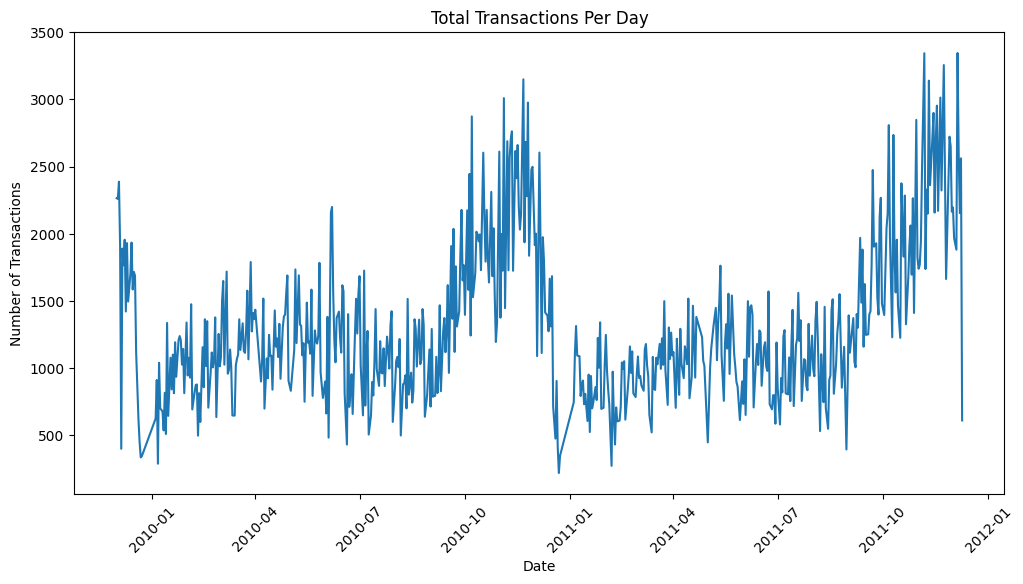

In [4]:
# ===== EDA: Transactions over time =====

import matplotlib.pyplot as plt

transactions_per_day = (
    df_base
    .groupby(df_base["InvoiceDate"].dt.date)
    .size()
)

plt.figure(figsize=(12,6))

plt.plot(transactions_per_day.index, transactions_per_day.values)

plt.title("Total Transactions Per Day")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.show()




### Daily Transaction Activity

The figure shows the total number of transactions per day across the dataset.

We observe significant fluctuations in daily activity, with transaction volumes varying substantially over time.  
This indicates that retail activity is highly dynamic and influenced by temporal patterns such as seasonal demand.

Because of this variability, detecting product trends cannot rely on simple thresholds.  
Instead, the model must capture relative changes and temporal signals in product behavior.

## Final Trend Label Construction and Dataset Export

A horizon-based trend label (`Y`) is constructed at the product–day level.  
For each product and day, a complete daily time series is built, including days with zero transactions, in order to preserve a consistent historical timeline.

Historical rolling statistics are then calculated using past data only, including a rolling mean, a rolling percentile over the recent window, and an expanding all-time percentile.  
A product–day is labeled as `Y = 1` if a significant demand burst occurs within the next **H = 10 days**.

The label is based on several conditions, including a minimum future transaction volume, deviation from recent and long-term historical behavior, and a minimum number of unique customers.  
All rolling statistics are shifted by one day to avoid data leakage.

Finally, the label is merged back into the transaction-level dataset, a revenue feature is added, and the final labeled dataset (`df_final`) is saved for the next stages of the project.

In [5]:
import numpy as np
import pandas as pd

# -----------------------------
# 0) Prep
# -----------------------------
H = 10  # Predict a trend within the next H days

df_tmp = df_base.copy()
df_tmp["Day"] = df_tmp["InvoiceDate"].dt.floor("D")

daily_raw = (
    df_tmp.groupby(["ProductID", "Day"])
    .agg(
        Transactions=("CustomerID", "count"),
        UniqueCustomers=("CustomerID", "nunique"),
    )
    .reset_index()
)

# -----------------------------
# 1)  active days
# -----------------------------
MIN_ACTIVE_DAYS = 14

active_products = (
    daily_raw.groupby("ProductID")["Day"]
    .nunique()
    .loc[lambda x: x >= MIN_ACTIVE_DAYS]
    .index
)

daily_raw = daily_raw[daily_raw["ProductID"].isin(active_products)].copy()

print(f"Products before filter : {df_tmp['ProductID'].nunique()}")
print(f"Products after filter  : {len(active_products)}")

# -----------------------------
# 2) Build COMPLETE daily grid per product
# -----------------------------
min_day = daily_raw["Day"].min()
max_day = daily_raw["Day"].max()
all_days = pd.date_range(min_day, max_day, freq="D")

grid = pd.MultiIndex.from_product(
    [active_products, all_days], names=["ProductID", "Day"]
).to_frame(index=False)

grid_size = len(active_products) * len(all_days)
print(f"\nGrid size: {len(active_products):,} products × {len(all_days):,} days = {grid_size:,} rows")
if grid_size > 3_000_000:
    print("  Warning: grid is large — may be slow or memory-heavy")

daily = (
    grid.merge(daily_raw, on=["ProductID", "Day"], how="left")
    .fillna({"Transactions": 0, "UniqueCustomers": 0})
    .sort_values(["ProductID", "Day"])
    .reset_index(drop=True)
)

daily["Transactions"] = daily["Transactions"].astype(int)
daily["UniqueCustomers"] = daily["UniqueCustomers"].astype(int)

# -----------------------------
# 3) Label function — H-day horizon
# -----------------------------
def build_y_percentile_horizon(
    daily_df: pd.DataFrame,
    H: int = 7,
    window: int = 30,
    q: float = 0.90,
    min_tx: int = 3,
    min_ratio: float = 1.15,
    min_unique: int = 2,
    min_periods: int = None,
    rm_floor: float = 1.0,
):
    
    if min_periods is None:
        min_periods = max(7, window // 2)

    
        d = daily_df.copy()
    d = d.sort_values(["ProductID", "Day"]).reset_index(drop=True)
    
    # Rolling stats (past-only) 
    d["rm"] = d.groupby("ProductID")["Transactions"].transform(
        lambda s: s.rolling(window, min_periods=min_periods).mean().shift(1)
    )
    d["rq"] = d.groupby("ProductID")["Transactions"].transform(
        lambda s: s.rolling(window, min_periods=min_periods).quantile(q).shift(1)
    )
    
    d["rq_alltime"] = d.groupby("ProductID")["Transactions"].transform(
        lambda s: s.expanding(min_periods=14).quantile(0.90).shift(1)
    )
    
    # Floor rm to avoid ratio trigger on near-zero history
    d["rm"] = d["rm"].clip(lower=rm_floor)

    # Future horizon targets: max Transactions and max UniqueCustomers in next H days
    future_tx = []
    future_unique = []
    g_tx = d.groupby("ProductID")["Transactions"]
    g_uc = d.groupby("ProductID")["UniqueCustomers"]

    for k in range(1, H + 1):
        future_tx.append(g_tx.shift(-k))
        future_unique.append(g_uc.shift(-k))

    d["Fmax"] = pd.concat(future_tx, axis=1).max(axis=1)
    d["Fmax_unique"] = pd.concat(future_unique, axis=1).max(axis=1)
    d["Y"] = (
        (d["Fmax"] >= min_tx) &                        
        (d["rq"] > 0) &                               
        (d["Fmax"] >= d["rq"]) &                      
        (d["rq_alltime"].notna()) &
        (d["Fmax"] >= d["rq_alltime"]) &               
        (d["Fmax"] >= min_ratio * d["rm"]) &           
        (d["Fmax_unique"] >= min_unique)              
    ).astype(int)
    

    # Drop edges: require history + require full horizon availability
    needed = ["rm", "rq", "Fmax", "Fmax_unique"]
    d = d.dropna(subset=needed).copy()

    metrics = {
        "H": H,
        "window": window,
        "q": q,
        "min_tx": min_tx,
        "min_ratio": min_ratio,
        "min_unique": min_unique,
        "min_periods": min_periods,
        "rm_floor": rm_floor,
        "rows_labeled": int(len(d)),
        "positives": int(d["Y"].sum()),
        "positive_rate_%": float(np.round(d["Y"].mean() * 100, 3)),
    }
    return metrics, d

# -----------------------------
# 4) Run
# -----------------------------

CHOSEN_WINDOW = 30
CHOSEN_RM_FLOOR = 1.0
CHOSEN_Q          = 0.90
CHOSEN_MIN_TX     = 3       
CHOSEN_MIN_RATIO  = 1.20   
CHOSEN_MIN_UNIQUE = 2

metrics, daily_labeled = build_y_percentile_horizon(
    daily,
    H=H,
    window=CHOSEN_WINDOW,
    q=CHOSEN_Q,
    min_tx=CHOSEN_MIN_TX,
    min_ratio=CHOSEN_MIN_RATIO,
    min_unique=CHOSEN_MIN_UNIQUE,
    rm_floor=CHOSEN_RM_FLOOR,
)

print("\nHorizon metrics:", metrics)
print("\nDaily-level Y distribution (%):")
print((daily_labeled["Y"].value_counts(normalize=True) * 100).round(3))

# -----------------------------
# 5) Merge back to transaction level
# -----------------------------
df_final = df_base.copy()
df_final["Day"] = df_final["InvoiceDate"].dt.floor("D")

df_final = df_final.merge(
    daily_labeled[["ProductID", "Day", "Y"]],
    on=["ProductID", "Day"],
    how="left"
)

df_final["Y"] = df_final["Y"].fillna(0).astype(int)
df_final = df_final.drop(columns=["Day"])

# Revenue feature
df_final["Revenue"] = df_final["Quantity"] * df_final["UnitPrice"]

df_final = df_final[[
    "ProductID", "Quantity", "UnitPrice", "Revenue",
    "CustomerID", "Country", "IsReturn", "InvoiceDate", "Y"
]]

print("\nTransaction-level Y distribution (%):")
print((df_final["Y"].value_counts(normalize=True) * 100).round(3))

# -----------------------------
# 6) Save
# -----------------------------
out_path = "cleaned_retail_data_with_Y.csv"
df_final.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")

Products before filter : 4638
Products after filter  : 3656

Grid size: 3,656 products × 739 days = 2,701,784 rows

Horizon metrics: {'H': 10, 'window': 30, 'q': 0.9, 'min_tx': 3, 'min_ratio': 1.2, 'min_unique': 2, 'min_periods': 15, 'rm_floor': 1.0, 'rows_labeled': 2643288, 'positives': 264486, 'positive_rate_%': 10.006}

Daily-level Y distribution (%):
Y
0    89.994
1    10.006
Name: proportion, dtype: float64

Transaction-level Y distribution (%):
Y
0    57.024
1    42.976
Name: proportion, dtype: float64

Saved: cleaned_retail_data_with_Y.csv


### Label Distribution and Interpretation

The positive rate is approximately **10.0% at the product-day level**, which was used to define the labels based on historical context.

However, when the labels are merged back to the **transaction level**, the positive rate appears significantly higher (around **43%**).

This discrepancy occurs because once a specific **product-day** is flagged as a trend, **all individual transactions** associated with that product on that day inherit the positive label.

As a result, the model is effectively trained to identify the underlying features that lead to these **high-activity daily patterns**, rather than focusing on individual transactions in isolation.

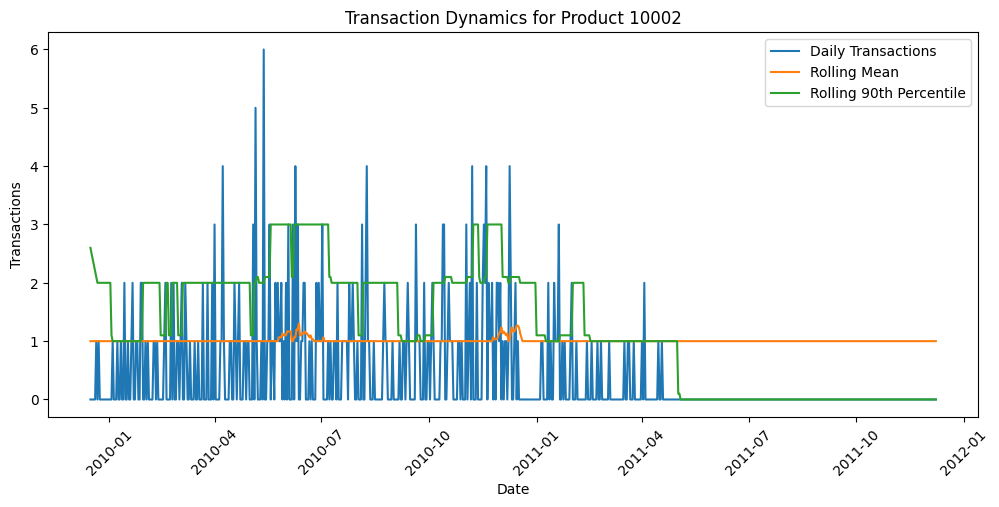

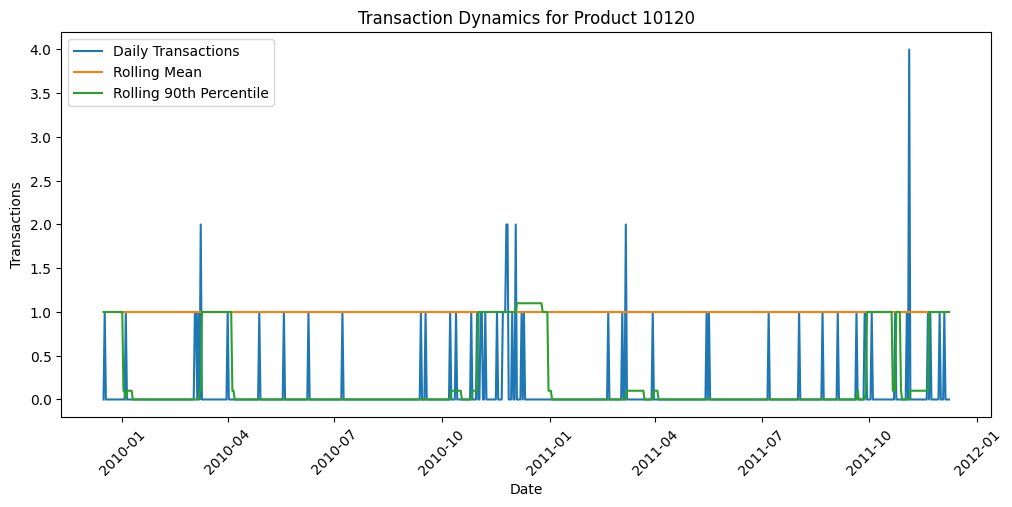

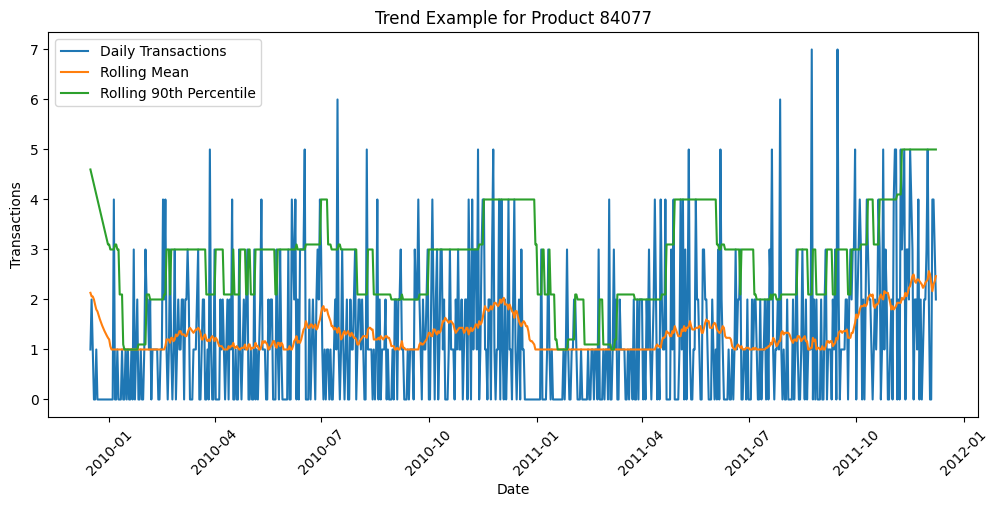

In [6]:
import matplotlib.pyplot as plt

trend_products = daily_labeled.loc[daily_labeled["Y"] == 1, "ProductID"].drop_duplicates().head(2)

for product_id in trend_products:
    sample = daily_labeled[daily_labeled["ProductID"] == product_id]

    plt.figure(figsize=(12, 5))
    plt.plot(sample["Day"], sample["Transactions"], label="Daily Transactions")
    plt.plot(sample["Day"], sample["rm"], label="Rolling Mean")
    plt.plot(sample["Day"], sample["rq"], label="Rolling 90th Percentile")

    plt.title(f"Transaction Dynamics for Product {product_id}")
    plt.xlabel("Date")
    plt.ylabel("Transactions")
    plt.legend()
    plt.xticks(rotation=45)
    plt.show()

    trend_counts = (
    daily_labeled[daily_labeled["Y"] == 1]
    .groupby("ProductID")
    .size()
    .sort_values(ascending=False)
)

trend_product = trend_counts.index[0]
sample = daily_labeled[daily_labeled["ProductID"] == trend_product]

plt.figure(figsize=(12, 5))
plt.plot(sample["Day"], sample["Transactions"], label="Daily Transactions")
plt.plot(sample["Day"], sample["rm"], label="Rolling Mean")
plt.plot(sample["Day"], sample["rq"], label="Rolling 90th Percentile")

plt.title(f"Trend Example for Product {trend_product}")
plt.xlabel("Date")
plt.ylabel("Transactions")
plt.legend()
plt.xticks(rotation=45)
plt.show()

### Trend Examples for Individual Products

The figures illustrate daily transaction patterns for several example products.

Each plot shows the daily number of transactions together with rolling statistics that represent the product's historical behavior.

The rolling mean captures the typical demand level, while the rolling 90th percentile represents unusually high activity compared to the recent past.

We observe different types of product behavior:
- products with occasional bursts of activity,
- low-volume products with sparse transactions,
- and products whose demand gradually increases over time.

These patterns motivate the need for a model that detects relative changes in demand rather than relying on fixed thresholds.

## Final Dataset Validation and Trend Overview

The labeled dataset (`df_final`) is loaded and validated to ensure that the preprocessing and labeling steps produced a consistent dataset.

Basic checks are performed on the dataset structure, including its shape, column names, data types, missing values, and duplicate rows.  
The distribution of the trend label `Y` is examined to confirm the class balance.

Additional statistics are computed to better understand the dataset, including the overall time range, the number of unique products and customers, and which products experienced trend events.

Finally, we identify products that were labeled as trends at least once and analyze how many trend days each product experienced.

In [7]:
# ===== Final Dataset Validation  =====
import pandas as pd

df_final = pd.read_csv("cleaned_retail_data_with_Y.csv")

# Fix datetime
df_final["InvoiceDate"] = pd.to_datetime(df_final["InvoiceDate"], errors="coerce")

print("Shape:", df_final.shape)

print("\nColumns:")
print(list(df_final.columns))

print("\nDtypes:")
print(df_final.dtypes)

print("\nMissing values:")
print(df_final.isnull().sum())

print("\nDuplicate rows:", df_final.duplicated().sum())

print("\nY distribution (counts):")
print(df_final["Y"].value_counts())

print("\nY distribution (%):")
print((df_final["Y"].value_counts(normalize=True) * 100).round(3))

print("\nTime range:")
print("Min date:", df_final["InvoiceDate"].min())
print("Max date:", df_final["InvoiceDate"].max())

print("\nUnique products:", df_final["ProductID"].nunique())
print("Unique customers:", df_final["CustomerID"].nunique())

# =========================
# ===== Trend Products =====
# =========================

# Products that were trend at least once
trend_products = df_final.loc[df_final["Y"] == 1, "ProductID"].unique()

print("\nNumber of products that were trend at least once:", len(trend_products))

print("\nSample of ProductIDs that were trend (first 20):")
print(trend_products[:20])

# Count trend days per product (product-day level)
df_tmp = df_final.copy()
df_tmp["Day"] = df_tmp["InvoiceDate"].dt.floor("D")

trend_days = (
    df_tmp[df_tmp["Y"] == 1]
    .groupby("ProductID")["Day"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nTop 10 products with most trend days:")
print(trend_days.head(10))

Shape: (794190, 9)

Columns:
['ProductID', 'Quantity', 'UnitPrice', 'Revenue', 'CustomerID', 'Country', 'IsReturn', 'InvoiceDate', 'Y']

Dtypes:
ProductID              object
Quantity                int64
UnitPrice             float64
Revenue               float64
CustomerID              int64
Country                object
IsReturn                 bool
InvoiceDate    datetime64[ns]
Y                       int64
dtype: object

Missing values:
ProductID      0
Quantity       0
UnitPrice      0
Revenue        0
CustomerID     0
Country        0
IsReturn       0
InvoiceDate    0
Y              0
dtype: int64

Duplicate rows: 0

Y distribution (counts):
Y
0    452882
1    341308
Name: count, dtype: int64

Y distribution (%):
Y
0    57.024
1    42.976
Name: proportion, dtype: float64

Time range:
Min date: 2009-12-01 07:45:00
Max date: 2011-12-09 12:50:00

Unique products: 4638
Unique customers: 5894

Number of products that were trend at least once: 2442

Sample of ProductIDs that were tren

## Product-Level Trend Label Overview

To better understand which products were identified as trends, we create a product-level summary table.  
For each `ProductID`, the trend label is determined by checking whether the product received at least one `Y = 1` event in the dataset.

The product descriptions are then retrieved from the original dataset and merged with the product-level labels to produce a readable table containing the product identifier, its description, and its trend label.

This table is saved as `product_trend_labels.csv` and is used only for inspection and validation of the labeling results.

In [8]:
import pandas as pd

# =========================
# Product-level trend label table
# =========================

# Load final labeled dataset
df_final = pd.read_csv("cleaned_retail_data_with_Y.csv")
df_final["ProductID"] = df_final["ProductID"].astype(str).str.strip()

# Product-level label: 1 if the product had at least one Y=1 event
product_trend = (
    df_final.groupby("ProductID")["Y"]
    .max()
    .reset_index()
    .rename(columns={"Y": "TrendLabel"})
)

# Build ProductID -> Description mapping from the raw dataset
product_desc = df[["StockCode", "Description"]].copy()
product_desc = product_desc.dropna(subset=["StockCode", "Description"]).copy()
product_desc["ProductID"] = product_desc["StockCode"].astype(str).str.strip()
product_desc["Description"] = product_desc["Description"].astype(str).str.strip()

# Keep one description per product
product_desc = (
    product_desc[["ProductID", "Description"]]
    .drop_duplicates()
    .groupby("ProductID", as_index=False)
    .first()
)

# Merge label with description
product_trend_full = product_trend.merge(product_desc, on="ProductID", how="left")

# Reorder columns
product_trend_full = product_trend_full[["ProductID", "Description", "TrendLabel"]]

# Display sample
display(product_trend_full.head(10))

# Save to CSV
out_path = "product_trend_labels.csv"
product_trend_full.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

,ProductID,Description,TrendLabel
0,10002,INFLATABLE POLITICAL GLOBE,1
1,10080,GROOVY CACTUS INFLATABLE,0
2,10109,BENDY COLOUR PENCILS,0
3,10120,DOGGY RUBBER,0
4,10123C,HEARTS WRAPPING TAPE,0
5,10123G,ARMY CAMO WRAPPING TAPE,0
6,10124A,SPOTS ON RED BOOKCOVER TAPE,0
7,10124G,ARMY CAMO BOOKCOVER TAPE,0
8,10125,MINI FUNKY DESIGN TAPES,1
9,10133,COLOURING PENCILS BROWN TUBE,1


Saved: product_trend_labels.csv


## Trend Label Definition and Modeling Strategy

The problem is defined at the product–day level. For each product, a complete daily time series is built including days with zero transactions, and all historical statistics are computed using past data only to prevent data leakage.

A product-day is labeled `Y = 1` if a significant demand burst is detected within a future horizon window. The labeling conditions combine multiple historical signals recent rolling statistics and long-term baselines to ensure that only genuine emerging trends are captured, and not routine seasonal spikes or one-time noise.

The model therefore learns to predict whether a product is about to experience a meaningful and broad-based acceleration in demand, based solely on its historical behavior up to the current day.

## Converting the Final Dataset to Spark and Building Daily Features

The final labeled dataset (`df_final`) is converted from a Pandas DataFrame to a Spark DataFrame in order to continue the analysis using Apache Spark.

After the conversion, the dataset is aggregated to a **product–day** level table.  
For each product and day, several daily activity features are calculated, including the number of transactions, total quantity sold, average price, number of unique customers, number of countries, and the return rate.

The trend label `Y` is also aggregated to the daily level so that each product–day observation contains both the engineered features and the corresponding label.

In [9]:
# ============================================================
# CONVERT df_final FROM PANDAS TO SPARK
# ============================================================
import pandas as pd
from pyspark.sql import SparkSession

#spark = SparkSession.builder.getOrCreate()

spark = SparkSession.builder \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()



if isinstance(df_final, pd.DataFrame):
    df_final = spark.createDataFrame(df_final)

print(type(df_final))
df_final.printSchema()
df_final.show(5)


# ============================================================
# BUILD DAILY SPARK TABLE FOR FEATURE ENGINEERING
# ============================================================
from pyspark.sql.functions import (
    col, to_timestamp, to_date, count, countDistinct,
    sum as _sum, avg as _avg, when, lit, max as _max
)

# source_df should be the transaction-level Spark DataFrame
source_df = df_final

# Make sure InvoiceDate is timestamp
source_df = source_df.withColumn("InvoiceDate", to_timestamp("InvoiceDate"))

# Build Day column
source_df = source_df.withColumn("Day", to_date("InvoiceDate"))

# Daily aggregation at ProductID-Day level
daily = (
    source_df
    .groupBy("ProductID", "Day")
    .agg(
        count("*").alias("tx_cnt"),
        _sum("Quantity").alias("qty_sum"),
        _avg("UnitPrice").alias("unitprice_mean"),
        countDistinct("CustomerID").alias("customers_cnt"),
        countDistinct("Country").alias("countries_cnt"),
        _avg(when(col("IsReturn") == 1, 1.0).otherwise(0.0)).alias("return_rate"),
        _max("Y").alias("Y")
    )
)

print("Daily schema:")
daily.printSchema()

print("Daily sample:")
daily.show(5, truncate=False)

<class 'pyspark.sql.dataframe.DataFrame'>
root
 |-- ProductID: string (nullable = true)
 |-- Quantity: long (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- Revenue: double (nullable = true)
 |-- CustomerID: long (nullable = true)
 |-- Country: string (nullable = true)
 |-- IsReturn: boolean (nullable = true)
 |-- InvoiceDate: string (nullable = true)
 |-- Y: long (nullable = true)



26/03/18 18:32:29 WARN TaskSetManager: Stage 0 contains a task of very large size (8442 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

+---------+--------+---------+-------+----------+--------------+--------+-------------------+---+
|ProductID|Quantity|UnitPrice|Revenue|CustomerID|       Country|IsReturn|        InvoiceDate|  Y|
+---------+--------+---------+-------+----------+--------------+--------+-------------------+---+
|    85048|      12|     6.95|   83.4|     13085|United Kingdom|   false|2009-12-01 07:45:00|  0|
|   79323P|      12|     6.75|   81.0|     13085|United Kingdom|   false|2009-12-01 07:45:00|  0|
|   79323W|      12|     6.75|   81.0|     13085|United Kingdom|   false|2009-12-01 07:45:00|  0|
|    22041|      48|      2.1|  100.8|     13085|United Kingdom|   false|2009-12-01 07:45:00|  0|
|    21232|      24|     1.25|   30.0|     13085|United Kingdom|   false|2009-12-01 07:45:00|  0|
+---------+--------+---------+-------+----------+--------------+--------+-------------------+---+
only showing top 5 rows

Daily schema:
root
 |-- ProductID: string (nullable = true)
 |-- Day: date (nullable = true)


26/03/18 18:32:31 WARN TaskSetManager: Stage 1 contains a task of very large size (8442 KiB). The maximum recommended task size is 1000 KiB.
[Stage 3:=============================>                             (2 + 2) / 4]

+---------+----------+------+-------+-----------------+-------------+-------------+-------------------+---+
|ProductID|Day       |tx_cnt|qty_sum|unitprice_mean   |customers_cnt|countries_cnt|return_rate        |Y  |
+---------+----------+------+-------+-----------------+-------------+-------------+-------------------+---+
|79323W   |2009-12-01|11    |91     |6.631818181818182|10           |1            |0.09090909090909091|0  |
|85183B   |2009-12-01|1     |60     |2.4              |1            |1            |0.0                |0  |
|84691    |2009-12-01|1     |12     |0.85             |1            |1            |0.0                |0  |
|20724    |2009-12-01|5     |110    |0.85             |5            |2            |0.0                |0  |
|20726    |2009-12-01|4     |34     |1.65             |4            |1            |0.0                |0  |
+---------+----------+------+-------+-----------------+-------------+-------------+-------------------+---+
only showing top 5 rows



## Feature Engineering and Model Dataset Preparation
This section builds the feature set used for predictive modeling.

Using the daily product-level table, we generate a wide range of features that describe how each product behaves over time. The features capture several aspects of product dynamics:

- **Transaction activity** – rolling averages, standard deviations, and lag values describing recent transaction behavior.
- **Momentum and trend signals** – growth rates, short-vs-long window comparisons, and indicators of consecutive increases that capture accelerating demand.
- **Burst and anomaly indicators** – signals comparing current activity to historical percentiles or averages to detect unusual spikes.
- **Price and quantity patterns** – changes in average price and sold quantity that may accompany emerging trends.
- **Customer and geographic spread** – indicators based on the number of customers and countries involved in recent transactions.
- **Seasonality features** – weekday, month, and week-of-year variables capturing temporal patterns.

Most signals are designed as **relative measures** (ratios or differences) rather than absolute values. This helps reduce popularity bias and allows the model to focus on **changes in behavior**, which is important for detecting emerging trends.

After generating the features, rows with insufficient historical data are removed to ensure valid calculations. A selected set of features (`feature_cols`) is then used to build the modeling dataset.

The data is split chronologically into **training, validation, and test sets**, and a `VectorAssembler` combines the selected columns into a single feature vector compatible with Spark ML models.

In [10]:

from pyspark.sql.functions import (
    col, sum as _sum, avg as _avg, when, max as _max, lit,
    dayofweek, month, weekofyear, stddev as _stddev,
    lag, percentile_approx, least
)
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler

spark = SparkSession.builder \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")


EPS = 1e-6
STD_FLOOR = 0.1
RATIO_CAP = 20.0

# -----------------------------
# Windows
# -----------------------------
w        = Window.partitionBy("ProductID").orderBy("Day")
w3       = w.rowsBetween(-3,  -1)
w7       = w.rowsBetween(-7,  -1)
w14      = w.rowsBetween(-14, -1)
w30      = w.rowsBetween(-30, -1)
w60_prev = w.rowsBetween(-60, -31)    

daily_base = daily.withColumn("weekday", dayofweek("Day"))
w_dow = Window.partitionBy("ProductID", "weekday").orderBy("Day").rowsBetween(-30, -1)

# -----------------------------
# Lag expressions
# -----------------------------
lag_tx_1        = lag("tx_cnt", 1).over(w)
lag_tx_2        = lag("tx_cnt", 2).over(w)    
lag_tx_3        = lag("tx_cnt", 3).over(w)    
lag_price_1     = lag("unitprice_mean", 1).over(w)
lag_qty_1       = lag("qty_sum", 1).over(w)
lag_customers_1 = lag("customers_cnt", 1).over(w)


# -----------------------------
# Feature engineering
# -----------------------------
daily_features = (
    daily_base

    # ---- transaction rolling stats
    .withColumn("rm_3",  _avg("tx_cnt").over(w3))
    .withColumn("rm_7",  _avg("tx_cnt").over(w7))
    .withColumn("rm_14", _avg("tx_cnt").over(w14))
    .withColumn("rm_30", _avg("tx_cnt").over(w30))                           
    .withColumn("rs_14", _stddev("tx_cnt").over(w14))
    .withColumn(
        "rs_14_safe",
        when(col("rs_14").isNull() | (col("rs_14") < lit(STD_FLOOR)), lit(STD_FLOOR)).otherwise(col("rs_14"))
    )

    # ---- lags and momentum
    .withColumn("lag_1", lag_tx_1)
    .withColumn("lag_2", lag_tx_2)                                           
    .withColumn("lag_3", lag_tx_3)                                           
    .withColumn("delta_1", col("tx_cnt") - col("lag_1"))
    .withColumn("growth_1_raw", col("tx_cnt") / (col("lag_1") + lit(EPS)))
    .withColumn("growth_1", least(col("growth_1_raw"), lit(RATIO_CAP)))
    .withColumn("sum_3", _sum("tx_cnt").over(w3))
    .withColumn("slope_7", col("rm_7") - col("rm_14"))
    .withColumn("is_up", when(col("delta_1") > 0, 1).otherwise(0))
    .withColumn("up_days_last_7", _sum("is_up").over(w7))
    .withColumn("z_14", (col("tx_cnt") - col("rm_14")) / col("rs_14_safe"))

    # ----  consecutive up days 
    .withColumn("up_1", when(col("tx_cnt") > col("lag_1"), lit(1)).otherwise(lit(0)))
    .withColumn("up_2", when(col("lag_1") > col("lag_2"), lit(1)).otherwise(lit(0)))
    .withColumn("up_3", when(col("lag_2") > col("lag_3"), lit(1)).otherwise(lit(0)))
    .withColumn("consec_up_3", col("up_1") * col("up_2") * col("up_3"))

    # ----  slope acceleration 
    .withColumn("lag_slope_3", lag("slope_7", 3).over(w))
    .withColumn("slope_acceleration", col("slope_7") - col("lag_slope_3"))

    # ---- short vs long window trend signals
    .withColumn("trend_signal_7_14_raw", col("rm_7") / (col("rm_14") + lit(EPS)))
    .withColumn("trend_signal_7_14", least(col("trend_signal_7_14_raw"), lit(RATIO_CAP)))

    # ----  rm7 vs rm30 — relative trend signal 
    .withColumn("rm7_vs_rm30_raw", col("rm_7") / (col("rm_30") + lit(EPS)))
    .withColumn("rm7_vs_rm30", least(col("rm7_vs_rm30_raw"), lit(RATIO_CAP)))

    # ---- seasonality / time
    .withColumn("month", month("Day"))
    .withColumn("week_of_year", weekofyear("Day"))

    # ---- quantile / burst-aligned signals
    .withColumn("rq_30", percentile_approx("tx_cnt", 0.9).over(w30))
    .withColumn("rq_14", percentile_approx("tx_cnt", 0.9).over(w14))
    .withColumn("dist_to_p90_raw", col("tx_cnt") / (col("rq_30") + lit(EPS)))
    .withColumn("dist_to_p90", least(col("dist_to_p90_raw"), lit(RATIO_CAP)))
    .withColumn("pct_above_rm", (col("tx_cnt") - col("rm_14")) / (col("rm_14") + lit(EPS)))
    .withColumn("is_above_mean", when(col("tx_cnt") > col("rm_14"), 1).otherwise(0))
    .withColumn("days_above_mean", _sum("is_above_mean").over(w7))

    # ---- price
    .withColumn("price_lag_1", lag_price_1)
    .withColumn("price_rm_7", _avg("unitprice_mean").over(w7))
    .withColumn("price_ratio_7_raw", col("unitprice_mean") / (col("price_rm_7") + lit(EPS)))
    .withColumn("price_ratio_7", least(col("price_ratio_7_raw"), lit(RATIO_CAP)))

    # ---- quantity
    .withColumn("qty_lag_1", lag_qty_1)
    .withColumn("qty_rm_7", _avg("qty_sum").over(w7))
    .withColumn("qty_rm_14", _avg("qty_sum").over(w14))
    .withColumn("qty_growth_1_raw", col("qty_sum") / (col("qty_lag_1") + lit(EPS)))
    .withColumn("qty_growth_1", least(col("qty_growth_1_raw"), lit(RATIO_CAP)))
    .withColumn("qty_trend_signal_raw", col("qty_rm_7") / (col("qty_rm_14") + lit(EPS)))
    .withColumn("qty_trend_signal", least(col("qty_trend_signal_raw"), lit(RATIO_CAP)))

    # ---- customer spread
    .withColumn("customers_rm_7",  _avg("customers_cnt").over(w7))
    .withColumn("customers_rm_14", _avg("customers_cnt").over(w14))
    .withColumn("customers_rm_prev60", _avg("customers_cnt").over(w60_prev))   
    .withColumn("customers_lag_1", lag_customers_1)
    .withColumn("customers_delta_1", col("customers_cnt") - col("customers_lag_1"))
    .withColumn("customers_per_tx", col("customers_cnt") / (col("tx_cnt") + lit(EPS)))
    .withColumn("customer_burst_signal_raw", col("customers_cnt") / (col("customers_rm_14") + lit(EPS)))
    .withColumn("customer_burst_signal", least(col("customer_burst_signal_raw"), lit(RATIO_CAP)))
    .withColumn("customer_trend_signal_raw", col("customers_rm_7") / (col("customers_rm_14") + lit(EPS)))
    .withColumn("customer_trend_signal", least(col("customer_trend_signal_raw"), lit(RATIO_CAP)))

    .withColumn("customers_rm14_vs_prev_raw",
        col("customers_rm_14") / (col("customers_rm_prev60") + lit(EPS)))
    .withColumn("customers_rm14_vs_prev",
        least(col("customers_rm14_vs_prev_raw"), lit(RATIO_CAP)))

    # ---- country spread
    .withColumn("countries_rm_14", _avg("countries_cnt").over(w14))
    .withColumn("countries_per_tx", col("countries_cnt") / (col("tx_cnt") + lit(EPS)))

    # ---- velocity
    .withColumn("vr_14_raw", col("tx_cnt") / (col("rm_14") + lit(EPS)))
    .withColumn("vr_14", least(col("vr_14_raw"), lit(RATIO_CAP)))

    # ---- day-of-week behavior
    .withColumn("tx_dow_avg", _avg("tx_cnt").over(w_dow))
    .withColumn("tx_vs_dow_raw", col("tx_cnt") / (col("tx_dow_avg") + lit(EPS)))
    .withColumn("tx_vs_dow", least(col("tx_vs_dow_raw"), lit(RATIO_CAP)))
)

# -----------------------------
# Drop rows with missing history
# -----------------------------
model_data = daily_features.dropna(subset=[
    "rm_3", "rm_7", "rm_14", "rm_30", "rs_14_safe",
    "lag_1", "lag_2", "lag_3",
    "delta_1", "growth_1", "sum_3", "slope_7", "up_days_last_7", "z_14",
    "consec_up_3", "slope_acceleration",
    "trend_signal_7_14", "rm7_vs_rm30",
    "month", "week_of_year",
    "rq_30", "rq_14", "dist_to_p90", "pct_above_rm", "days_above_mean",
    "price_lag_1", "price_rm_7", "price_ratio_7",
    "qty_lag_1", "qty_rm_7", "qty_rm_14", "qty_growth_1", "qty_trend_signal",
    "customers_rm_7", "customers_rm_14", "customers_rm_prev60",
    "customers_lag_1", "customers_delta_1",
    "customers_per_tx", "customer_burst_signal", "customer_trend_signal",
    "customers_rm14_vs_prev",
    "countries_rm_14", "countries_per_tx",
    "vr_14",
    "tx_dow_avg", "tx_vs_dow",
    "weekday"
])

print("Model rows:", model_data.count())


feature_cols = [
    # base
    "tx_cnt", "qty_sum", "unitprice_mean", "customers_cnt", "countries_cnt",

    # tx momentum — relative
    "rm_3", "rm_7", "rs_14_safe",
    "lag_1", "delta_1", "growth_1", "sum_3",
    "slope_7", "up_days_last_7", "z_14",
    "trend_signal_7_14",
    "rm7_vs_rm30",              
    "consec_up_3",              
    "slope_acceleration",      

    # time
    "weekday", "month", "week_of_year",

    # burst-aligned
    "rq_30", "rq_14", "dist_to_p90", "pct_above_rm", "days_above_mean",

    # price
    "price_lag_1", "price_rm_7", "price_ratio_7",

    # quantity
    "qty_lag_1", "qty_rm_7", "qty_rm_14", "qty_growth_1", "qty_trend_signal",

    # customer spread — relative
    "customers_delta_1", "customers_per_tx",
    "customer_burst_signal", "customer_trend_signal",
    "customers_rm14_vs_prev",  

    # country spread
    "countries_rm_14", "countries_per_tx",

    # velocity
    "vr_14",

    # day-of-week
    "tx_dow_avg", "tx_vs_dow",
]

print("Total features:", len(feature_cols))

# -----------------------------
# drop rows with nulls in actual model features
# -----------------------------
model_data_clean = model_data.dropna(subset=feature_cols + ["Y"])

print("Rows before clean:", model_data.count())
print("Rows after clean :", model_data_clean.count())


# -----------------------------
# Time split: Train / Validation / Test
# -----------------------------
train_end_date = "2011-08-15"
test_start_date = "2011-10-01"

train_data = model_data_clean.filter(col("Day") < train_end_date).cache()

validation_data = model_data_clean.filter(
    (col("Day") >= train_end_date) & (col("Day") < test_start_date)
).cache()

test_data = model_data_clean.filter(col("Day") >= test_start_date).cache()

print("Train:", train_data.count(), "| Validation:", validation_data.count(), "| Test:", test_data.count())

print("\n=== Train label distribution ===")
train_data.groupBy("Y").count().show()

print("\n=== Validation label distribution ===")
validation_data.groupBy("Y").count().show()

print("\n=== Test label distribution ===")
test_data.groupBy("Y").count().show()

# -----------------------------
# Vector assembler
# -----------------------------
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="skip"
)

train_vector = assembler.transform(train_data).cache()
validation_vector = assembler.transform(validation_data).cache()
test_vector = assembler.transform(test_data).cache()

print("Train vector rows     :", train_vector.count())
print("Validation vector rows:", validation_vector.count())
print("Test vector rows      :", test_vector.count())

train_vector.select("ProductID", "Day", "features", "Y").show(5, truncate=False)

# -----------------------------
# Sanity checks
# -----------------------------
for feat in ["trend_signal_7_14", "rm7_vs_rm30", "customers_rm14_vs_prev",
             "consec_up_3", "slope_acceleration", "dist_to_p90", "tx_vs_dow"]:
    print(f"=== {feat} ===")
    model_data_clean.select(feat).describe().show()

Model rows: 332158
Total features: 45


Rows before clean: 332158


Rows after clean : 332158


Train: 247884 | Validation: 27673 | Test: 56601

=== Train label distribution ===
+---+------+
|  Y| count|
+---+------+
|  0|156115|
|  1| 91769|
+---+------+


=== Validation label distribution ===
+---+-----+
|  Y|count|
+---+-----+
|  0|16509|
|  1|11164|
+---+-----+


=== Test label distribution ===
+---+-----+
|  Y|count|
+---+-----+
|  0|31595|
|  1|25006|
+---+-----+



Train vector rows     : 247884
Validation vector rows: 27673
Test vector rows      : 56601
+---------+----------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+
|ProductID|Day       |features                                                                                                                                                                                                                                                                                                                                           

+-------+-------------------+
|summary|  trend_signal_7_14|
+-------+-------------------+
|  count|             332158|
|   mean| 1.0007983141536436|
| stddev|0.13724125535062182|
|    min|0.14893614803078645|
|    max| 1.7117114958201716|
+-------+-------------------+

=== rm7_vs_rm30 ===


... (3 outputs left out)

+-------+--------------------+
|summary|  slope_acceleration|
+-------+--------------------+
|  count|              332158|
|   mean|-3.96541060923667...|
| stddev|  0.3432020819501995|
|    min|  -5.142857142857142|
|    max|   4.571428571428571|
+-------+--------------------+

=== dist_to_p90 ===


+-------+--------------------+
|summary|         dist_to_p90|
+-------+--------------------+
|  count|              332158|
|   mean|  0.6722831714170168|
| stddev| 0.40090366285651813|
|    min|0.055555552469135974|
|    max|  13.999986000014001|
+-------+--------------------+

=== tx_vs_dow ===


[Stage 278:===============================================>         (5 + 1) / 6]

+-------+-------------------+
|summary|          tx_vs_dow|
+-------+-------------------+
|  count|             332158|
|   mean| 0.9976347062542538|
| stddev| 0.5882161272100207|
|    min|0.07826086344045416|
|    max| 14.999987500010418|
+-------+-------------------+



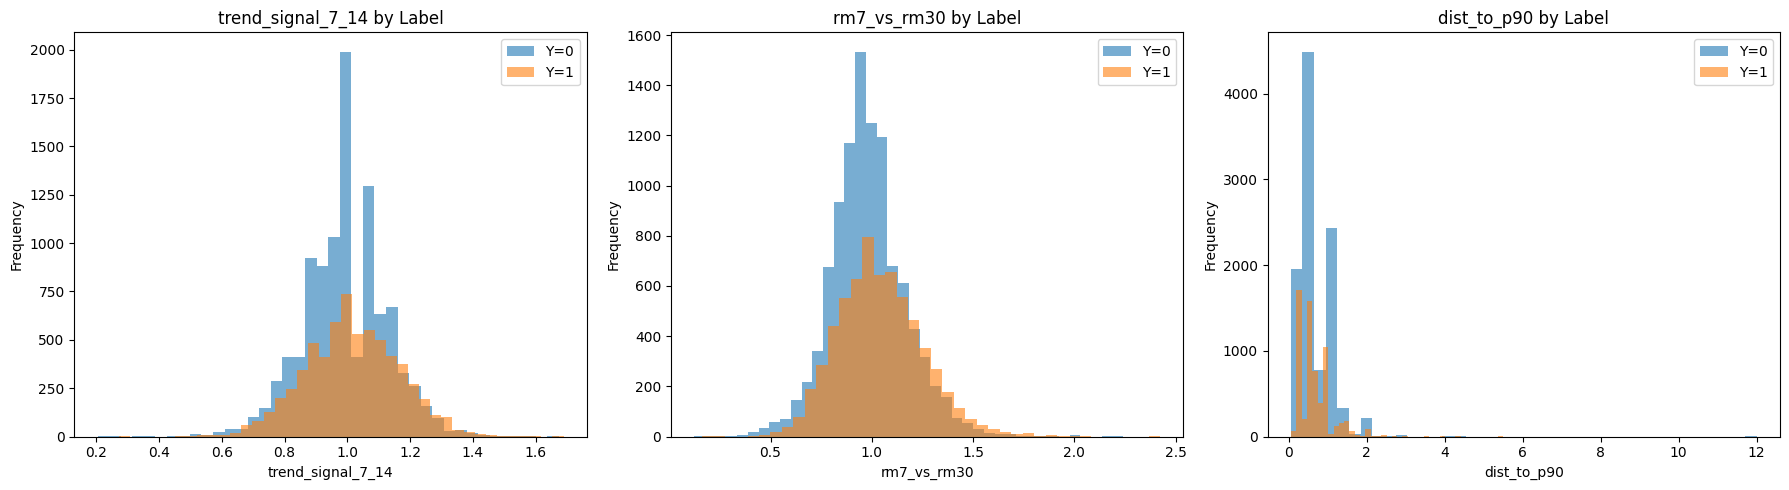

In [11]:
# ===== Feature visualization: selected features by label =====

import matplotlib.pyplot as plt
import pandas as pd

# Take a small sample from Spark to Pandas for plotting
plot_features = ["trend_signal_7_14", "rm7_vs_rm30", "dist_to_p90", "Y"]

plot_df = (
    model_data_clean
    .select(*plot_features)
    .sample(withReplacement=False, fraction=0.05, seed=42)
    .toPandas()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feat in zip(axes, ["trend_signal_7_14", "rm7_vs_rm30", "dist_to_p90"]):
    ax.hist(plot_df[plot_df["Y"] == 0][feat], bins=40, alpha=0.6, label="Y=0")
    ax.hist(plot_df[plot_df["Y"] == 1][feat], bins=40, alpha=0.6, label="Y=1")
    ax.set_title(f"{feat} by Label")
    ax.set_xlabel(feat)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

### Feature Distribution by Label

The figure shows the distribution of several engineered features for trend (Y=1) and non-trend (Y=0) observations.

These features capture relative changes in product demand over time, such as short-term acceleration and distance from historical high activity levels.

We observe that trend observations tend to appear at higher values of these signals, indicating stronger recent activity compared to historical behavior.

This suggests that the engineered features capture meaningful signals that help distinguish emerging trends from normal product behavior.

## Random Forest Training, Weight Tuning, and Threshold Evaluation
This section trains the first predictive model using a Random Forest classifier.

A baseline Random Forest model is first trained on the training dataset and evaluated on the validation set using the **PR-AUC (Area Under the Precision–Recall Curve)** metric, which is appropriate for imbalanced classification problems such as trend detection.

Because the dataset contains significantly fewer trend events (`Y=1`) than non-trend observations, different **positive class weights** are tested. For each candidate weight, a new model is trained and evaluated on the validation set, and the configuration with the highest PR-AUC is selected.

After selecting the best model, the predicted probability of a trend (`p_trend`) is extracted from the model output. Multiple probability thresholds are then evaluated to analyze the trade-off between:

- number of generated alerts
- precision (how many detected trends are correct)
- recall (how many real trends are captured)
- F1 score

This step helps determine which threshold provides the most practical balance between detecting real trends and limiting false positives.

Finally, **feature importance** is extracted from the best Random Forest model to identify which engineered features contribute the most to the prediction of emerging product trends.

In [12]:
# ============================================================
# RANDOM FOREST - STAGE 1 PIPELINE (Train -> Validation)
# baseline + weight search + thresholds + feature importance
# ============================================================
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col, when, lit, sum as _sum
import pandas as pd

spark.sparkContext.setLogLevel("ERROR")

# -----------------------------
# 1) Cache vectors
# -----------------------------
train_vector = train_vector.cache()
validation_vector = validation_vector.cache()
test_vector = test_vector.cache()

train_vector.count()
validation_vector.count()
test_vector.count()

# -----------------------------
# 2) Evaluator
# -----------------------------
evaluator_pr = BinaryClassificationEvaluator(
    labelCol="Y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

# -----------------------------
# 3) Baseline (Train -> Validation)
# -----------------------------
rf_base = RandomForestClassifier(
    labelCol="Y",
    featuresCol="features",
    numTrees=100,
    maxDepth=8,
    maxBins=64,
    featureSubsetStrategy="sqrt",
    seed=42
)

rf_base_model = rf_base.fit(train_vector)
base_val_pred = rf_base_model.transform(validation_vector).cache()
base_pr_auc = evaluator_pr.evaluate(base_val_pred)

print(f"Baseline RF PR-AUC on validation (no weight): {round(base_pr_auc, 6)}")

# -----------------------------
# 4) Weighted search (Train -> Validation)
# -----------------------------
weight_candidates = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
best = (-1.0, None, None, None)  

for w_pos in weight_candidates:
    train_w = train_vector.withColumn(
        "weight",
        when(col("Y") == 1, lit(float(w_pos))).otherwise(lit(1.0))
    )

    rf = RandomForestClassifier(
        labelCol="Y",
        featuresCol="features",
        weightCol="weight",
        numTrees=100,
        maxDepth=6,
        maxBins=44,
        featureSubsetStrategy="sqrt",
        seed=42
    )

    model = rf.fit(train_w)
    pred = model.transform(validation_vector)
    pr_auc = evaluator_pr.evaluate(pred)

    print(f"pos_weight={w_pos:<5}  RF validation PR-AUC={pr_auc:.6f}")

    if pr_auc > best[0]:
        best = (pr_auc, w_pos, pred, model)

best_pr, best_w, best_val_pred, best_model = best
print(f"\nBEST pos_weight = {best_w}  |  Validation PR-AUC = {round(best_pr, 6)}")

# -----------------------------
# 5) Add p_trend on validation predictions
# -----------------------------
best_val_pred = (
    best_val_pred
    .withColumn("p_trend", vector_to_array(col("probability"))[1])
    .cache()
)
best_val_pred.count()

# -----------------------------
# 6) Threshold evaluation on validation
# -----------------------------
thresholds = [0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30]

print("\n=== Threshold Evaluation — Best RF Model (Validation) ===")

for t in thresholds:
    stats = (
        best_val_pred
        .withColumn("y_hat", when(col("p_trend") >= t, 1).otherwise(0))
        .select(
            _sum(((col("Y") == 1) & (col("y_hat") == 1)).cast("int")).alias("tp"),
            _sum(((col("Y") == 0) & (col("y_hat") == 1)).cast("int")).alias("fp"),
            _sum(((col("Y") == 1) & (col("y_hat") == 0)).cast("int")).alias("fn"),
            _sum((col("y_hat") == 1).cast("int")).alias("alerts"),
        )
        .collect()[0]
    )

    tp, fp, fn, alerts = int(stats.tp), int(stats.fp), int(stats.fn), int(stats.alerts)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    print(f"\nThreshold={t} | Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
    print(f"Precision={round(precision,4)} | Recall={round(recall,4)} | F1={round(f1,4)}")

# -----------------------------
# 7) Feature importance
# -----------------------------
feat_imp_rf = (
    pd.DataFrame({
        "feature": feature_cols,
        "importance": best_model.featureImportances.toArray()
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nTop 10 Most Important Features (Best RF):")
print(feat_imp_rf.head(10).to_string(index=False))

Baseline RF PR-AUC on validation (no weight): 0.718665


pos_weight=1.0    RF validation PR-AUC=0.712094


pos_weight=1.5    RF validation PR-AUC=0.709541


pos_weight=2.0    RF validation PR-AUC=0.707188


pos_weight=3.0    RF validation PR-AUC=0.704011


pos_weight=4.0    RF validation PR-AUC=0.701605


pos_weight=5.0    RF validation PR-AUC=0.700857


pos_weight=7.0    RF validation PR-AUC=0.700064


pos_weight=10.0   RF validation PR-AUC=0.698784

BEST pos_weight = 1.0  |  Validation PR-AUC = 0.712094

=== Threshold Evaluation — Best RF Model (Validation) ===

Threshold=0.1 | Alerts=27673 | TP=11164 FP=16509 FN=0
Precision=0.4034 | Recall=1.0 | F1=0.5749

Threshold=0.12 | Alerts=24712 | TP=11045 FP=13667 FN=119
Precision=0.4469 | Recall=0.9893 | F1=0.6157

Threshold=0.15 | Alerts=21673 | TP=10758 FP=10915 FN=406
Precision=0.4964 | Recall=0.9636 | F1=0.6552

Threshold=0.18 | Alerts=19082 | TP=10356 FP=8726 FN=808
Precision=0.5427 | Recall=0.9276 | F1=0.6848

Threshold=0.2 | Alerts=17886 | TP=10096 FP=7790 FN=1068
Precision=0.5645 | Recall=0.9043 | F1=0.6951

Threshold=0.25 | Alerts=15599 | TP=9444 FP=6155 FN=1720
Precision=0.6054 | Recall=0.8459 | F1=0.7058

Threshold=0.3 | Alerts=13845 | TP=8813 FP=5032 FN=2351
Precision=0.6365 | Recall=0.7894 | F1=0.7048

Top 10 Most Important Features (Best RF):
     feature  importance
       rq_30    0.161851
        rm_7    0.160808
  rs_14_s

## Two-Stage Modeling: Stage-2 Model Comparison and Threshold Selection

A second modeling stage is introduced to reduce false positives produced by the first Random Forest model.

The first model (Stage-1) generates a probability score for each observation. Cases with a probability above a predefined base threshold are considered **potential trend candidates** and are passed to the second stage for further filtering.

Only these candidate observations are used to build a Stage-2 dataset. The data is split chronologically into a Stage-2 training set and a Stage-2 validation set to preserve the temporal structure of the problem.

Several models are evaluated for Stage-2, including **Logistic Regression, Random Forest, and Gradient Boosted Trees (GBT)**. Each model is trained on the Stage-2 training data and evaluated on the Stage-2 validation data using classification metrics such as precision, recall, and F1 score.

After selecting the best Stage-2 model, different probability thresholds are tested to determine the threshold that provides the best balance between detecting true trends and reducing false alerts.

In [13]:
# ============================================================
# TWO-STAGE MODEL COMPARISON 
# Stage 1 = best RF trained on TRAIN
# Stage 2 = trained on hard cases from VALIDATION
# Evaluation here = on stage2_valid
# ============================================================

from pyspark.sql.functions import col, when, sum as _sum
from pyspark.ml.functions import vector_to_array
from pyspark.ml.classification import (
    LogisticRegression,
    RandomForestClassifier,
    GBTClassifier
)

# -----------------------------
# 1) Build hard cases from VALIDATION predictions of stage 1
# -----------------------------
BASE_THRESHOLD = 0.30
FINAL_THRESHOLD = 0.50

stage2_all_val = (
    best_val_pred
    .withColumn("stage1_pred", when(col("p_trend") >= BASE_THRESHOLD, 1).otherwise(0))
    .filter(col("stage1_pred") == 1)
    .drop("prediction", "rawPrediction", "probability")   # remove stage-1 output cols
    .cache()
)

print("Stage2 ALL validation dataset size:", stage2_all_val.count())
stage2_all_val.groupBy("Y").count().show()

# -----------------------------
# 2) Split hard cases by time into stage2_train / stage2_valid
#    (inside validation period)
# -----------------------------
stage2_split_date = "2011-09-10"

stage2_train = stage2_all_val.filter(col("Day") < stage2_split_date).cache()
stage2_valid = stage2_all_val.filter(col("Day") >= stage2_split_date).cache()

print("Stage2 train size:", stage2_train.count())
print("Stage2 valid size:", stage2_valid.count())

print("\n=== Stage2 train label distribution ===")
stage2_train.groupBy("Y").count().show()

print("\n=== Stage2 valid label distribution ===")
stage2_valid.groupBy("Y").count().show()

# -----------------------------
# 3) Candidate stage-2 models
# -----------------------------
stage2_models = {
    "LogisticRegression": LogisticRegression(
        labelCol="Y",
        featuresCol="features",
        maxIter=100,
        regParam=0.01,
        elasticNetParam=0.0
    ),
    "RandomForest": RandomForestClassifier(
        labelCol="Y",
        featuresCol="features",
        numTrees=60,
        maxDepth=6,
        seed=42
    ),
    "GBT": GBTClassifier(
        labelCol="Y",
        featuresCol="features",
        maxIter=60,
        maxDepth=5,
        seed=42
    )
}

print("\n=== Stage-2 Model Comparison (evaluated on stage2_valid) ===")

results = []
best_stage2 = (-1.0, None, None, None)  

for model_name, model in stage2_models.items():
    fitted_model = model.fit(stage2_train)

    pred_valid = (
        fitted_model
        .transform(stage2_valid)
        .withColumn("p_stage2", vector_to_array(col("probability"))[1])
        .withColumn(
            "final_prediction",
            when(col("p_stage2") >= FINAL_THRESHOLD, 1).otherwise(0)
        )
        .cache()
    )

    stats = (
        pred_valid
        .select(
            _sum(((col("Y") == 1) & (col("final_prediction") == 1)).cast("int")).alias("tp"),
            _sum(((col("Y") == 0) & (col("final_prediction") == 1)).cast("int")).alias("fp"),
            _sum(((col("Y") == 1) & (col("final_prediction") == 0)).cast("int")).alias("fn"),
            _sum((col("final_prediction") == 1).cast("int")).alias("alerts")
        )
        .collect()[0]
    )

    tp = int(stats.tp)
    fp = int(stats.fp)
    fn = int(stats.fn)
    alerts = int(stats.alerts)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    results.append((model_name, alerts, tp, fp, fn, precision, recall, f1))

    if f1 > best_stage2[0]:
        best_stage2 = (f1, model_name, fitted_model, pred_valid)

    print(f"\n=== {model_name} ===")
    print(f"Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
    print(f"Precision={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f}")

# -----------------------------
# 4) Show sorted summary
# -----------------------------
results_sorted = sorted(results, key=lambda x: x[7], reverse=True)

print("\n=== Sorted by F1 (best first) ===")
for r in results_sorted:
    print(
        f"{r[0]:18s} | Alerts={r[1]:6d} | TP={r[2]:6d} | FP={r[3]:6d} | FN={r[4]:6d} "
        f"| Precision={r[5]:.4f} | Recall={r[6]:.4f} | F1={r[7]:.4f}"
    )

best_stage2_f1, best_stage2_name, best_stage2_model, best_stage2_valid_pred = best_stage2
print(f"\nBEST STAGE-2 MODEL = {best_stage2_name} | Validation F1 = {best_stage2_f1:.4f}")

# ============================================================
# STAGE 2 - Threshold tuning on stage2_valid for best model
# ============================================================

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

print(f"\n=== Stage-2 Threshold Tuning for {best_stage2_name} ===")

best_threshold = None
best_threshold_f1 = -1.0

for t in thresholds:
    tmp = best_stage2_valid_pred.withColumn(
        "final_prediction",
        when(col("p_stage2") >= t, 1).otherwise(0)
    )

    stats = (
        tmp
        .select(
            _sum(((col("Y") == 1) & (col("final_prediction") == 1)).cast("int")).alias("tp"),
            _sum(((col("Y") == 0) & (col("final_prediction") == 1)).cast("int")).alias("fp"),
            _sum(((col("Y") == 1) & (col("final_prediction") == 0)).cast("int")).alias("fn"),
            _sum((col("final_prediction") == 1).cast("int")).alias("alerts")
        )
        .collect()[0]
    )

    tp = int(stats.tp)
    fp = int(stats.fp)
    fn = int(stats.fn)
    alerts = int(stats.alerts)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    if f1 > best_threshold_f1:
        best_threshold_f1 = f1
        best_threshold = t

    print(f"\nThreshold={t} | Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
    print(f"Precision={precision:.4f} | Recall={recall:.4f} | F1={f1:.4f}")

print(f"\nBEST STAGE-2 THRESHOLD = {best_threshold} | Validation F1 = {best_threshold_f1:.4f}")

Stage2 ALL validation dataset size: 13845


+---+-----+
|  Y|count|
+---+-----+
|  0| 5032|
|  1| 8813|
+---+-----+

Stage2 train size: 6538
Stage2 valid size: 7307

=== Stage2 train label distribution ===
+---+-----+
|  Y|count|
+---+-----+
|  0| 2971|
|  1| 3567|
+---+-----+


=== Stage2 valid label distribution ===
+---+-----+
|  Y|count|
+---+-----+
|  0| 2061|
|  1| 5246|
+---+-----+


=== Stage-2 Model Comparison (evaluated on stage2_valid) ===



=== LogisticRegression ===
Alerts=6782 | TP=4944 FP=1838 FN=302
Precision=0.7290 | Recall=0.9424 | F1=0.8221

=== RandomForest ===
Alerts=6441 | TP=4805 FP=1636 FN=441
Precision=0.7460 | Recall=0.9159 | F1=0.8223



=== GBT ===
Alerts=5653 | TP=4291 FP=1362 FN=955
Precision=0.7591 | Recall=0.8180 | F1=0.7874

=== Sorted by F1 (best first) ===
RandomForest       | Alerts=  6441 | TP=  4805 | FP=  1636 | FN=   441 | Precision=0.7460 | Recall=0.9159 | F1=0.8223
LogisticRegression | Alerts=  6782 | TP=  4944 | FP=  1838 | FN=   302 | Precision=0.7290 | Recall=0.9424 | F1=0.8221
GBT                | Alerts=  5653 | TP=  4291 | FP=  1362 | FN=   955 | Precision=0.7591 | Recall=0.8180 | F1=0.7874

BEST STAGE-2 MODEL = RandomForest | Validation F1 = 0.8223

=== Stage-2 Threshold Tuning for RandomForest ===



Threshold=0.3 | Alerts=7275 | TP=5228 FP=2047 FN=18
Precision=0.7186 | Recall=0.9966 | F1=0.8351

Threshold=0.35 | Alerts=7246 | TP=5217 FP=2029 FN=29
Precision=0.7200 | Recall=0.9945 | F1=0.8353

Threshold=0.4 | Alerts=7133 | TP=5169 FP=1964 FN=77
Precision=0.7247 | Recall=0.9853 | F1=0.8351

Threshold=0.45 | Alerts=6801 | TP=5008 FP=1793 FN=238
Precision=0.7364 | Recall=0.9546 | F1=0.8314

Threshold=0.5 | Alerts=6441 | TP=4805 FP=1636 FN=441
Precision=0.7460 | Recall=0.9159 | F1=0.8223

Threshold=0.55 | Alerts=5795 | TP=4426 FP=1369 FN=820
Precision=0.7638 | Recall=0.8437 | F1=0.8017

Threshold=0.6 | Alerts=4693 | TP=3717 FP=976 FN=1529
Precision=0.7920 | Recall=0.7085 | F1=0.7480

Threshold=0.65 | Alerts=3289 | TP=2677 FP=612 FN=2569
Precision=0.8139 | Recall=0.5103 | F1=0.6273

Threshold=0.7 | Alerts=1741 | TP=1434 FP=307 FN=3812
Precision=0.8237 | Recall=0.2734 | F1=0.4105

BEST STAGE-2 THRESHOLD = 0.35 | Validation F1 = 0.8353


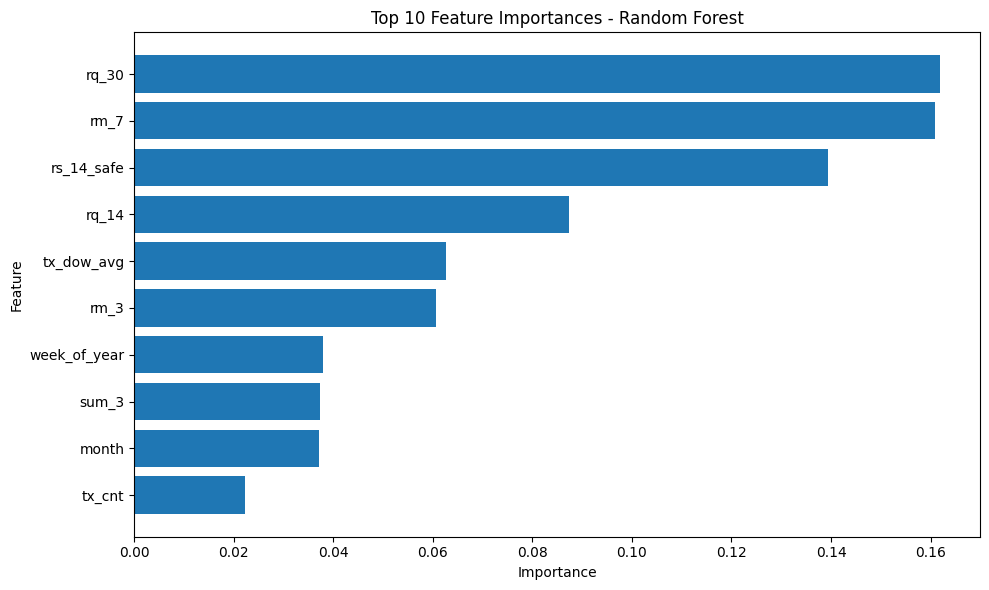

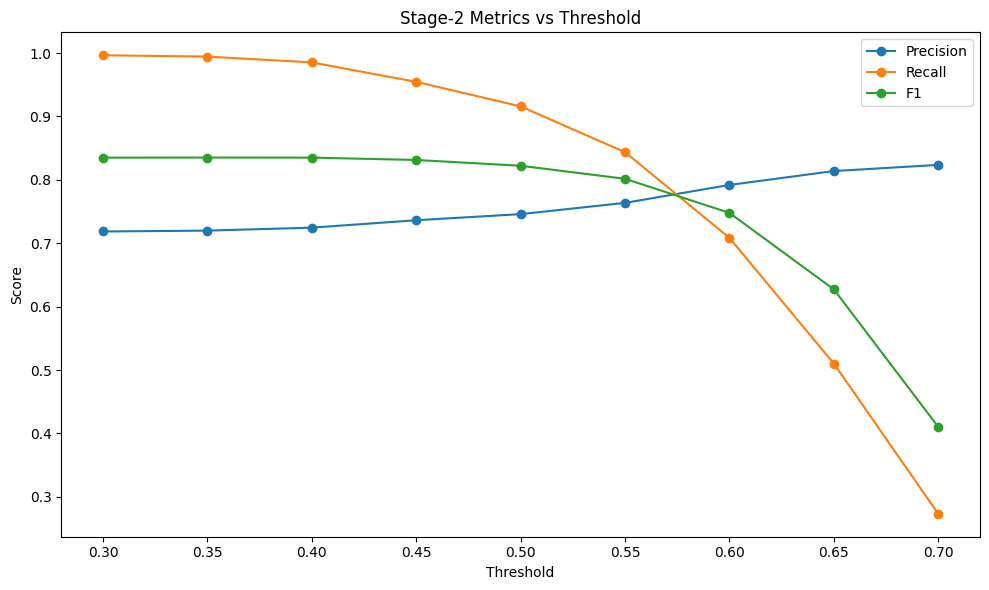

In [14]:
# ===== Feature Importance Plot (Random Forest) =====

import matplotlib.pyplot as plt

top_rf = feat_imp_rf.head(10).iloc[::-1]  # reverse for nicer barh plot

plt.figure(figsize=(10, 6))
plt.barh(top_rf["feature"], top_rf["importance"])

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# ===== Stage-2 Threshold Plot =====

import matplotlib.pyplot as plt

thresholds_plot = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

precisions = []
recalls = []
f1s = []

for t in thresholds_plot:
    tmp = best_stage2_valid_pred.withColumn(
        "final_prediction",
        when(col("p_stage2") >= t, 1).otherwise(0)
    )

    stats = (
        tmp
        .select(
            _sum(((col("Y") == 1) & (col("final_prediction") == 1)).cast("int")).alias("tp"),
            _sum(((col("Y") == 0) & (col("final_prediction") == 1)).cast("int")).alias("fp"),
            _sum(((col("Y") == 1) & (col("final_prediction") == 0)).cast("int")).alias("fn")
        )
        .collect()[0]
    )

    tp = int(stats.tp)
    fp = int(stats.fp)
    fn = int(stats.fn)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)

plt.figure(figsize=(10, 6))
plt.plot(thresholds_plot, precisions, marker="o", label="Precision")
plt.plot(thresholds_plot, recalls, marker="o", label="Recall")
plt.plot(thresholds_plot, f1s, marker="o", label="F1")

plt.title("Stage-2 Metrics vs Threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()

plt.tight_layout()
plt.show()

### Model Interpretation and Threshold Selection

The first figure presents the **top 10 feature importances** according to the Random Forest model.  
Feature importance reflects how much each feature contributes to the model’s predictions when identifying emerging product trends.

The most influential features mainly capture historical demand levels, short-term activity patterns, and seasonal effects.  
This indicates that the model relies on signals related to unusual activity and demand acceleration relative to the product’s historical behavior.

The second figure shows how **precision, recall, and F1 score vary across different decision thresholds** for the Stage-2 model.  
Increasing the threshold makes the model more conservative: precision increases slightly, while recall decreases.  
The optimal threshold is selected based on the highest F1 score, which balances the trade-off between detecting true trends and limiting false alerts.

In this case, the best performing threshold is approximately **0.35**, providing the best balance between precision and recall.

**Feature descriptions**

- **rq_30** - Rolling 90th percentile of transactions over the previous 30 days, capturing unusually high demand levels.
- **rm_7** - Rolling mean of transactions over the last 7 days, representing short-term demand.
- **rs_14_safe** - Standard deviation of transactions over 14 days, capturing demand volatility.
- **rq_14** - Rolling 90th percentile of transactions over the past 14 days.
- **tx_dow_avg** - Average number of transactions for the same day of the week, capturing weekly seasonality.
- **rm_3** - Rolling mean of transactions over the previous 3 days, representing very recent activity.
- **week_of_year** - Week index capturing broader seasonal demand patterns.
- **sum_3** - Total number of transactions during the last 3 days, capturing short bursts of activity.
- **month** - Calendar month representing long-term seasonal effects.
- **customers_cnt** - Number of unique customers purchasing the product on that day, reflecting customer demand intensity.

## Final Evaluation on the Held-Out Test Set

After completing model selection and threshold tuning on the validation set, the next step is to evaluate the final selected architecture on the **held-out test set**.

The purpose of this evaluation is to estimate how the system performs on **unseen future data** that was not used during training or model selection.  
This is especially important in this project because the test period is intended to simulate a realistic future scenario, similar to the behavior expected later in the real-time streaming pipeline.

At this stage, we evaluate:

1. **Stage-1 alone** - the selected Random Forest model using the chosen Stage-1 threshold.
2. **The full two-stage pipeline** - Stage-1 followed by the selected Stage-2 model using the chosen Stage-2 threshold.

This allows us to answer two important questions:

- How well does the selected model generalize to unseen data?
- Does the second stage provide a meaningful improvement over the first stage alone?

The following cell computes the final test metrics for both configurations, including:

- number of alerts
- true positives (TP)
- false positives (FP)
- false negatives (FN)
- precision
- recall
- F1-score

This evaluation is used only for **final performance reporting**, and not for further model selection.

In [15]:
# ============================================================
# FINAL EVALUATION ON TEST SET
# Full two-stage pipeline:
# Stage 1 (RF) -> filter by threshold -> Stage 2 -> final metrics
# ============================================================

from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col, when, sum as _sum

# -----------------------------
# 1) Chosen final thresholds
# -----------------------------
STAGE1_THRESHOLD = 0.25
STAGE2_THRESHOLD = 0.35

# -----------------------------
# 2) Stage-1 prediction on TEST
# -----------------------------
test_stage1_pred = (
    best_model
    .transform(test_vector)
    .withColumn("p_trend", vector_to_array(col("probability"))[1])
    .withColumn(
        "stage1_pred",
        when(col("p_trend") >= STAGE1_THRESHOLD, 1).otherwise(0)
    )
    .cache()
)

print("Total test rows:", test_stage1_pred.count())

# -----------------------------
# 3) Stage-1 metrics on TEST
# -----------------------------
stage1_stats = (
    test_stage1_pred
    .select(
        _sum(((col("Y") == 1) & (col("stage1_pred") == 1)).cast("int")).alias("tp"),
        _sum(((col("Y") == 0) & (col("stage1_pred") == 1)).cast("int")).alias("fp"),
        _sum(((col("Y") == 1) & (col("stage1_pred") == 0)).cast("int")).alias("fn"),
        _sum((col("stage1_pred") == 1).cast("int")).alias("alerts")
    )
    .collect()[0]
)

tp1 = int(stage1_stats.tp)
fp1 = int(stage1_stats.fp)
fn1 = int(stage1_stats.fn)
alerts1 = int(stage1_stats.alerts)

precision1 = tp1 / (tp1 + fp1) if (tp1 + fp1) > 0 else 0.0
recall1 = tp1 / (tp1 + fn1) if (tp1 + fn1) > 0 else 0.0
f1_1 = (2 * precision1 * recall1 / (precision1 + recall1)) if (precision1 + recall1) > 0 else 0.0

print("\n=== Stage-1 FINAL TEST RESULTS ===")
print(f"Threshold={STAGE1_THRESHOLD} | Alerts={alerts1} | TP={tp1} FP={fp1} FN={fn1}")
print(f"Precision={precision1:.4f} | Recall={recall1:.4f} | F1={f1_1:.4f}")

# -----------------------------
# 4) Keep only Stage-1 positives for Stage-2
# -----------------------------
test_stage2_input = (
    test_stage1_pred
    .filter(col("stage1_pred") == 1)
    .drop("prediction", "rawPrediction", "probability")
    .cache()
)

print("\nRows passed to Stage-2:", test_stage2_input.count())
print("Stage-2 input label distribution:")
test_stage2_input.groupBy("Y").count().show()

# -----------------------------
# 5) Stage-2 prediction on TEST
# -----------------------------
test_stage2_pred = (
    best_stage2_model
    .transform(test_stage2_input)
    .withColumn("p_stage2", vector_to_array(col("probability"))[1])
    .withColumn(
        "final_prediction",
        when(col("p_stage2") >= STAGE2_THRESHOLD, 1).otherwise(0)
    )
    .cache()
)

# -----------------------------
# 6) Final two-stage metrics on TEST
# -----------------------------
final_stats = (
    test_stage2_pred
    .select(
        _sum(((col("Y") == 1) & (col("final_prediction") == 1)).cast("int")).alias("tp"),
        _sum(((col("Y") == 0) & (col("final_prediction") == 1)).cast("int")).alias("fp"),
        _sum(((col("Y") == 1) & (col("final_prediction") == 0)).cast("int")).alias("fn_inside_stage2"),
        _sum((col("final_prediction") == 1).cast("int")).alias("alerts")
    )
    .collect()[0]
)

tp2 = int(final_stats.tp)
fp2 = int(final_stats.fp)
fn_inside_stage2 = int(final_stats.fn_inside_stage2)
alerts2 = int(final_stats.alerts)


stage1_missed_positive = fn1
total_fn = stage1_missed_positive + fn_inside_stage2

precision2 = tp2 / (tp2 + fp2) if (tp2 + fp2) > 0 else 0.0
recall2 = tp2 / (tp2 + total_fn) if (tp2 + total_fn) > 0 else 0.0
f1_2 = (2 * precision2 * recall2 / (precision2 + recall2)) if (precision2 + recall2) > 0 else 0.0

print("\n=== FINAL TWO-STAGE TEST RESULTS ===")
print(f"Stage-1 Threshold={STAGE1_THRESHOLD} | Stage-2 Threshold={STAGE2_THRESHOLD}")
print(f"Final Alerts={alerts2} | TP={tp2} FP={fp2} FN={total_fn}")
print(f"Precision={precision2:.4f} | Recall={recall2:.4f} | F1={f1_2:.4f}")

# -----------------------------
# 7) Optional summary table
# -----------------------------
summary_rows = [
    ("Stage-1 only", STAGE1_THRESHOLD, None, alerts1, tp1, fp1, fn1, precision1, recall1, f1_1),
    ("Two-Stage final", STAGE1_THRESHOLD, STAGE2_THRESHOLD, alerts2, tp2, fp2, total_fn, precision2, recall2, f1_2),
]

summary_df = spark.createDataFrame(
    summary_rows,
    ["Pipeline", "Stage1_Threshold", "Stage2_Threshold", "Alerts", "TP", "FP", "FN", "Precision", "Recall", "F1"]
)

print("\n=== TEST SUMMARY TABLE ===")
summary_df.show(truncate=False)



# Save final model
model_path = "trend_rf_model"

best_model.write().overwrite().save(model_path)

print("Model saved to:", model_path)

Total test rows: 56601

=== Stage-1 FINAL TEST RESULTS ===
Threshold=0.25 | Alerts=38122 | TP=22033 FP=16089 FN=2973
Precision=0.5780 | Recall=0.8811 | F1=0.6980



Rows passed to Stage-2: 38122
Stage-2 input label distribution:
+---+-----+
|  Y|count|
+---+-----+
|  0|16089|
|  1|22033|
+---+-----+




=== FINAL TWO-STAGE TEST RESULTS ===
Stage-1 Threshold=0.25 | Stage-2 Threshold=0.35
Final Alerts=37771 | TP=21914 FP=15857 FN=3092
Precision=0.5802 | Recall=0.8763 | F1=0.6982

=== TEST SUMMARY TABLE ===
+---------------+----------------+----------------+------+-----+-----+----+------------------+------------------+------------------+
|Pipeline       |Stage1_Threshold|Stage2_Threshold|Alerts|TP   |FP   |FN  |Precision         |Recall            |F1                |
+---------------+----------------+----------------+------+-----+-----+----+------------------+------------------+------------------+
|Stage-1 only   |0.25            |NULL            |38122 |22033|16089|2973|0.5779602329363622|0.8811085339518515|0.698042073248004 |
|Two-Stage final|0.25            |0.35            |37771 |21914|15857|3092|0.5801805618066771|0.8763496760777414|0.6981537824362426|
+---------------+----------------+----------------+------+-----+-----+----+------------------+------------------+----------------

Model saved to: trend_rf_model


## Model Experiments Summary

### Stage-1 Model Comparison (Validation)

| Model | Threshold | Precision | Recall | F1 | Alerts |
|------|----------|-----------|--------|------|--------|
| **Random Forest** | 0.25 | 0.6054 | 0.8459 | **0.7058** | 15599 |
| **GBT** | 0.30 | 0.5701 | 0.9076 | 0.7003 | 17773 |
| **HistGradientBoosting** | 0.30 | 0.5537 | 0.9233 | 0.6922 | 18618 |
| **XGBoost** | 0.30 | 0.5568 | 0.9177 | 0.6931 | 18400 |

Several classifiers were evaluated on the validation set.  
**Random Forest achieved the best F1 score and was selected as the Stage-1 model.**

---

### Two-Stage Strategy

To further improve precision, a **two-stage approach** was explored:

- **Stage-1** generates candidates with high recall (captures most trends).
- **Stage-2** filters false positives among those candidates.

---

### Stage-2 Model Comparison (Validation)

| Model | Precision | Recall | F1 | Alerts |
|-------|-----------|--------|--------|--------|
| Random Forest | 0.7460 | 0.9159 | **0.8223** | 6441 |
| Logistic Regression | 0.7290 | 0.9424 | 0.8221 | 6782 |
| GBT | 0.7591 | 0.8180 | 0.7874 | 5653 |

While Random Forest was also used in Stage-1, its reuse in Stage-2 is intentional.  
In Stage-1, the model serves as a high-recall filter, whereas in Stage-2 it is retrained on a more challenging subset of data to refine predictions and reduce false positives.  
This multi-stage approach allows the same model architecture to specialize in different tasks across the pipeline.

---

### Final Evaluation on Test Set

| Pipeline | Precision | Recall | F1 | Alerts |
|----------|-----------|--------|--------|--------|
| Stage-1 only | 0.5780 | 0.8811 | 0.6980 | 38122 |
| Two-Stage pipeline | 0.5802 | 0.8763 | 0.6982 | 37771 |

When evaluated on the held-out test set, the two-stage pipeline achieved very similar performance to Stage-1 alone, with only a marginal improvement in F1 score (0.6982 vs 0.6980).

While the overall performance remained nearly unchanged, the two-stage pipeline slightly reduced the number of false positives and total alerts (by ~350 alerts), indicating a modest refinement of predictions.

---

# Architecture Decision

Since the second stage provided **no measurable improvement on unseen data**,  
the final system uses a **single Random Forest model**.

This simplifies the pipeline **without any loss in performance**.

Although the two-stage pipeline was tested to reduce false positives,  
the final evaluation on unseen test data showed that **Stage-1 (Random Forest) already captures the trend dynamics effectively (F1 ≈ 0.70)**.

To minimize system complexity and reduce **inference latency** in a production environment,  
the **single-stage model** was selected for final deployment.

## Kafka Ingestion Layer - System Initialization (Streaming Phase)

At this stage, we implemented the ingestion layer of our real-time streaming architecture using Apache Kafka and integrated it with Spark Structured Streaming.

The Kafka-based streaming environment consists of the following core components:

- **ZooKeeper** - Responsible for cluster coordination and configuration management. It ensures that the Kafka broker is properly registered and operational.

- **Kafka Broker** - The central message server that receives events from producers, stores them in topics, and makes them available to streaming consumers.

- **Topic (`retail_stream`)** - A logical channel used to organize and store real-time retail purchase events.

- **Producer (Python Script – `producer_simulation.py`)** - Simulates real-time e-commerce transactions by streaming records from the cleaned dataset into Kafka in burst patterns, mimicking production-like ingestion behavior.

- **Spark Structured Streaming Consumer (`spark_streaming_consumer.py`)** - Replaces the console consumer and continuously reads events from Kafka, processing them in micro-batches for real-time analytics and trend detection.

This setup establishes a fully operational real-time ingestion pipeline:

**Producer → Kafka → Spark Structured Streaming**

The system is now ready for the next phase of the project: window-based aggregations, baseline comparison, and stateful acceleration detection using Spark.

# Appendix: Alternative Model Experiments

During the model selection phase, three additional classifiers were tested as alternative Stage-1 models: GBT, HistGradientBoosting, and XGBoost. The training cells are commented out to avoid unnecessary execution time. The results of all experiments are summarized in the Model Experiments Summary table above.

### GBT (Gradient Boosted Trees)
Evaluated as an alternative Stage-1 model using the same training and validation split. A weighted search was performed to handle class imbalance, and multiple thresholds were tested to analyze the precision-recall trade-off.

### HistGradientBoosting 
Evaluated outside Spark ML, requiring conversion of feature vectors to NumPy arrays. A baseline with `class_weight="balanced"` was tested first, followed by automated hyperparameter tuning using Optuna to maximize PR-AUC on the validation set.

### XGBoost
Evaluated outside Spark ML. Class imbalance was handled using `scale_pos_weight`, and early stopping was applied on an inner split derived from the training set, keeping the validation set untouched for final evaluation.

## Alternative Experiment: GBT (Gradient Boosted Trees)

In [16]:
# # ============================================================
# # GBT — STAGE 1 PIPELINE (Train -> Validation)
# # weighted search + eval + feature importance
# # ============================================================
# from pyspark.sql import SparkSession
# from pyspark.ml.classification import GBTClassifier
# from pyspark.ml.evaluation import BinaryClassificationEvaluator
# from pyspark.ml.functions import vector_to_array
# from pyspark.sql.functions import col, when, lit, sum as _sum
# import pandas as pd

# spark = SparkSession.builder.getOrCreate()
# spark.sparkContext.setLogLevel("ERROR")

# # -----------------------------
# # 1) Cache vectors
# # -----------------------------
# train_vector = train_vector.cache()
# validation_vector = validation_vector.cache()
# test_vector = test_vector.cache()

# train_vector.count()
# validation_vector.count()
# test_vector.count()

# # -----------------------------
# # 2) Evaluator
# # -----------------------------
# evaluator_pr = BinaryClassificationEvaluator(
#     labelCol="Y",
#     rawPredictionCol="rawPrediction",
#     metricName="areaUnderPR"
# )

# # -----------------------------
# # 3) Baseline (Train -> Validation)
# # -----------------------------
# gbt_base = GBTClassifier(
#     labelCol="Y",
#     featuresCol="features",
#     maxIter=80,
#     maxDepth=6,
#     stepSize=0.05,
#     subsamplingRate=0.8,
#     seed=42
# )

# gbt_base_model = gbt_base.fit(train_vector)
# base_val_pred = gbt_base_model.transform(validation_vector).cache()
# base_pr_auc = evaluator_pr.evaluate(base_val_pred)

# print(f"Baseline GBT PR-AUC on validation (no weight): {round(base_pr_auc, 6)}")

# # -----------------------------
# # 4) Weighted search (Train -> Validation)
# # -----------------------------
# weight_candidates = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
# best = (-1.0, None, None, None)   # (pr_auc, weight, pred_on_validation, model)

# for w_pos in weight_candidates:
#     train_w = train_vector.withColumn(
#         "weight",
#         when(col("Y") == 1, lit(float(w_pos))).otherwise(lit(1.0))
#     )

#     gbt = GBTClassifier(
#         labelCol="Y",
#         featuresCol="features",
#         weightCol="weight",
#         maxIter=80,
#         maxDepth=6,
#         stepSize=0.05,
#         subsamplingRate=0.8,
#         seed=42
#     )

#     model = gbt.fit(train_w)
#     pred = model.transform(validation_vector)
#     pr_auc = evaluator_pr.evaluate(pred)

#     print(f"pos_weight={w_pos:<5}  Validation PR-AUC={pr_auc:.6f}")

#     if pr_auc > best[0]:
#         best = (pr_auc, w_pos, pred, model)

# best_pr, best_w, best_val_pred, best_model = best

# print(f"\nBEST pos_weight = {best_w}  |  Validation PR-AUC = {round(best_pr, 6)}")

# # -----------------------------
# # 5) Add p_trend on validation predictions
# # -----------------------------
# best_val_pred = (
#     best_val_pred
#     .withColumn("p_trend", vector_to_array(col("probability"))[1])
#     .cache()
# )
# best_val_pred.count()

# # -----------------------------
# # 6) Threshold evaluation on validation
# # -----------------------------
# thresholds = [0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30]
# print("\n=== Threshold Evaluation — Best GBT Model (Validation) ===")

# for t in thresholds:
#     stats = (
#         best_val_pred
#         .withColumn("y_hat", when(col("p_trend") >= t, 1).otherwise(0))
#         .select(
#             _sum(((col("Y") == 1) & (col("y_hat") == 1)).cast("int")).alias("tp"),
#             _sum(((col("Y") == 0) & (col("y_hat") == 1)).cast("int")).alias("fp"),
#             _sum(((col("Y") == 1) & (col("y_hat") == 0)).cast("int")).alias("fn"),
#             _sum((col("y_hat") == 1).cast("int")).alias("alerts"),
#         )
#         .collect()[0]
#     )

#     tp, fp, fn, alerts = int(stats.tp), int(stats.fp), int(stats.fn), int(stats.alerts)

#     precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
#     recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
#     f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

#     print(f"\nThreshold={t} | Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
#     print(f"Precision={round(precision,4)} | Recall={round(recall,4)} | F1={round(f1,4)}")

# # -----------------------------
# # 7) Feature importance
# # -----------------------------
# feat_imp = (
#     pd.DataFrame({
#         "feature": feature_cols,
#         "importance": best_model.featureImportances.toArray()
#     })
#     .sort_values("importance", ascending=False)
#     .reset_index(drop=True)
# )

# print("\nTop 10 Most Important Features (Best GBT):")
# print(feat_imp.head(10).to_string(index=False))

## Alternative Experiment: HistGradientBoosting 

In [17]:
# # ============================================================
# # HISTGRADIENTBOOSTING — STAGE 1 PIPELINE (Train -> Validation)
# # install + balanced + optuna + final model + thresholds
# # ============================================================
# #!pip install optuna -q

# import optuna
# from sklearn.ensemble import HistGradientBoostingClassifier
# from sklearn.metrics import average_precision_score
# from pyspark.ml.functions import vector_to_array
# from pyspark.sql.functions import col
# import numpy as np

# optuna.logging.set_verbosity(optuna.logging.WARNING)

# # ============================================================
# # Step 1 — Convert Spark vectors to NumPy
# # ============================================================
# train_pd = (
#     train_vector
#     .select(vector_to_array(col("features")).alias("features_arr"), col("Y"))
#     .toPandas()
# )

# validation_pd = (
#     validation_vector
#     .select(vector_to_array(col("features")).alias("features_arr"), col("Y"))
#     .toPandas()
# )

# X_train = np.vstack(train_pd["features_arr"].values)
# y_train = train_pd["Y"].values.astype(int)

# X_val = np.vstack(validation_pd["features_arr"].values)
# y_val = validation_pd["Y"].values.astype(int)

# print("X_train shape:", X_train.shape)
# print("X_val shape  :", X_val.shape)

# # ============================================================
# # Step 2 — Quick test with class_weight=balanced only
# # ============================================================
# hgb_balanced = HistGradientBoostingClassifier(
#     max_iter=200,
#     learning_rate=0.05,
#     max_depth=6,
#     min_samples_leaf=30,
#     class_weight="balanced",
#     random_state=42
# )

# hgb_balanced.fit(X_train, y_train)
# p_balanced_val = hgb_balanced.predict_proba(X_val)[:, 1]

# print("Validation PR-AUC (balanced only):", round(average_precision_score(y_val, p_balanced_val), 4))

# # ============================================================
# # Step 3 — Optuna hyperparameter search (Train -> Validation)
# # ============================================================
# def objective(trial):
#     params = {
#         "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
#         "max_iter":          trial.suggest_int("max_iter", 200, 600),
#         "max_depth":         trial.suggest_int("max_depth", 4, 10),
#         "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 20, 150),
#         "l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 5.0, log=True),
#         "max_leaf_nodes":    trial.suggest_int("max_leaf_nodes", 20, 80),
#         "class_weight":      "balanced",
#         "random_state":      42,
#     }

#     model = HistGradientBoostingClassifier(**params)
#     model.fit(X_train, y_train)
#     proba = model.predict_proba(X_val)[:, 1]
#     return average_precision_score(y_val, proba)

# study = optuna.create_study(direction="maximize")
# study.optimize(objective, n_trials=50, show_progress_bar=True)

# print("\nBest Validation PR-AUC:", round(study.best_value, 4))
# print("Best params:", study.best_params)

# # ============================================================
# # Step 4 — Train final model with best params (still evaluate on validation)
# # ============================================================
# best_hgb = HistGradientBoostingClassifier(
#     **study.best_params,
#     class_weight="balanced",
#     random_state=42
# )

# best_hgb.fit(X_train, y_train)
# p_best_val = best_hgb.predict_proba(X_val)[:, 1]

# print("\n=== Results Comparison (Validation) ===")
# print(f"Balanced only:     PR-AUC = {round(average_precision_score(y_val, p_balanced_val), 4)}")
# print(f"Optuna + balanced: PR-AUC = {round(average_precision_score(y_val, p_best_val), 4)}")

# # ============================================================
# # Step 5 — Threshold evaluation on best model (Validation)
# # ============================================================
# thresholds = [0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30]
# print("\n=== Threshold Evaluation — Best HistGB Model (Validation) ===")

# for t in thresholds:
#     y_hat = (p_best_val >= t).astype(int)

#     tp = int(((y_val == 1) & (y_hat == 1)).sum())
#     fp = int(((y_val == 0) & (y_hat == 1)).sum())
#     fn = int(((y_val == 1) & (y_hat == 0)).sum())
#     alerts = int((y_hat == 1).sum())

#     precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
#     recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
#     f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

#     print(f"\nThreshold={t} | Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
#     print(f"Precision={round(precision,4)} | Recall={round(recall,4)} | F1={round(f1,4)}")

## Alternative Experiment: XGBoost

In [18]:
# # ============================================================
# # XGBOOST - STAGE 1 PIPELINE (Train -> Validation)
# # convert + class imbalance + early stopping + thresholds + feature importance
# # ============================================================
# from xgboost import XGBClassifier
# from sklearn.metrics import average_precision_score
# from sklearn.model_selection import train_test_split
# from pyspark.ml.functions import vector_to_array
# from pyspark.sql.functions import col
# import numpy as np
# import pandas as pd

# # ============================================================
# # Step 1  Convert Spark vectors to NumPy
# # ============================================================
# train_pd = (
#     train_vector
#     .select(vector_to_array(col("features")).alias("features_arr"), col("Y"))
#     .toPandas()
# )

# validation_pd = (
#     validation_vector
#     .select(vector_to_array(col("features")).alias("features_arr"), col("Y"))
#     .toPandas()
# )

# X_train = np.vstack(train_pd["features_arr"].values).astype(np.float32)
# y_train = train_pd["Y"].values.astype(int)

# X_val = np.vstack(validation_pd["features_arr"].values).astype(np.float32)
# y_val = validation_pd["Y"].values.astype(int)

# print("X_train shape:", X_train.shape)
# print("X_val shape  :", X_val.shape)

# # ============================================================
# # Step 2  Handle class imbalance
# # ============================================================
# pos = (y_train == 1).sum()
# neg = (y_train == 0).sum()
# scale_pos_weight = neg / pos if pos > 0 else 1.0

# print("Positive samples:", int(pos))
# print("Negative samples:", int(neg))
# print("scale_pos_weight:", round(scale_pos_weight, 4))

# # ============================================================
# # Step 3 - Inner split from TRAIN for early stopping
# # IMPORTANT:
# # early stopping uses only TRAIN-derived data
# # VALIDATION remains untouched for real evaluation
# # ============================================================
# X_tr, X_es, y_tr, y_es = train_test_split(
#     X_train, y_train,
#     test_size=0.1,
#     random_state=42,
#     stratify=y_train
# )

# print("X_tr shape:", X_tr.shape)
# print("X_es shape:", X_es.shape)

# # ============================================================
# # Step 4  Train model
# # ============================================================
# xgb = XGBClassifier(
#     n_estimators=600,
#     max_depth=6,
#     learning_rate=0.05,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     reg_alpha=0.1,
#     reg_lambda=1.5,
#     min_child_weight=10,
#     objective="binary:logistic",
#     eval_metric="aucpr",
#     early_stopping_rounds=30,
#     random_state=42,
#     n_jobs=-1,
#     scale_pos_weight=scale_pos_weight
# )

# xgb.fit(
#     X_tr, y_tr,
#     eval_set=[(X_es, y_es)],
#     verbose=50
# )

# print(f"\nBest iteration: {xgb.best_iteration}")

# # ============================================================
# # Step 5  Evaluate on VALIDATION
# # ============================================================
# p_val = xgb.predict_proba(X_val)[:, 1]
# pr_auc = average_precision_score(y_val, p_val)
# print("XGBoost Validation PR-AUC:", round(pr_auc, 4))

# # ============================================================
# # Step 6  Threshold evaluation on VALIDATION
# # ============================================================
# thresholds = [0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30]
# print("\n=== Threshold Evaluation — XGBoost (Validation) ===")

# for t in thresholds:
#     y_hat = (p_val >= t).astype(int)

#     tp = int(((y_val == 1) & (y_hat == 1)).sum())
#     fp = int(((y_val == 0) & (y_hat == 1)).sum())
#     fn = int(((y_val == 1) & (y_hat == 0)).sum())
#     alerts = int((y_hat == 1).sum())

#     precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
#     recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
#     f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

#     print(f"\nThreshold={t} | Alerts={alerts} | TP={tp} FP={fp} FN={fn}")
#     print(f"Precision={round(precision,4)} | Recall={round(recall,4)} | F1={round(f1,4)}")

# # ============================================================
# # Step 7  Feature importance
# # ============================================================
# feat_imp_xgb = (
#     pd.DataFrame({
#         "feature": feature_cols,
#         "importance": xgb.feature_importances_
#     })
#     .sort_values("importance", ascending=False)
#     .reset_index(drop=True)
# )

# print("\nTop 10 Most Important Features (XGBoost):")
# print(feat_imp_xgb.head(10).to_string(index=False))